# Redes neurais para previsão de *Churn* Bancário

**Objetivo:** construir uma rede neural MLP que preveja quais clientes de um banco europeu vão encerrar a conta (*churn*), para que a área comercial possa agir antes.

**Frameworks:** este notebook implementa a mesma MLP em **dois frameworks, lado a lado**:

| Framework | Por quê |
|---|---|
| **PyTorch** | exigido pelo enunciado da tarefa |
| **MLX** (Apple) | desafio opcional, aceito e integrado; otimizado para chips Apple Silicon |

Os dois usam **exatamente os mesmos dados, a mesma divisão, o mesmo pré-processamento e o mesmo laço de treino** (mesma ordem de embaralhamento dos lotes, mesmo *Early Stopping*). A única diferença é o framework que calcula os gradientes, o que permite comparar os dois de forma justa.

> **MAC:** as células marcadas com *MAC* só mostram seu resultado "de verdade" num Mac com chip Apple Silicon (M1, M2...). No PC (Linux/WSL), o MLX roda em **CPU**; no Mac ele usa a **GPU (Metal)** automaticamente. O notebook roda do início ao fim nos dois ambientes, sem mudar nada no código. Os textos de análise que dependem dos resultados (Partes 4 a 7) são **gerados por código** a partir dos números de cada execução, então continuam corretos quando o notebook é executado no Mac.

**Roteiro:**
1. Análise exploratória
2. Pré-processamento
3. Modelo de referência e primeira rede neural
4. Ajuste de hiperparâmetros e regularização
5. Desbalanceamento e avaliação final
6. Interpretação e recomendações
7. Extra: otimização com MLX
8. Questões teóricas
9. Entregáveis

## 0. Configuração do ambiente

Importei as bibliotecas e **fixei as sementes aleatórias** (`random`, `numpy`, PyTorch e MLX) para que os resultados sejam reproduzíveis. Todas as divisões usam `random_state=42`.

A célula também detecta se o notebook está rodando num Mac com Apple Silicon.

In [1]:
import os, random, time, json, platform, warnings
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
import joblib
from IPython.display import Markdown, display

import torch
import torch.nn as tnn
import torch.nn.functional as TF

import mlx.core as mx
import mlx.nn as mnn
import mlx.optimizers as mopt
from mlx.utils import tree_flatten, tree_unflatten

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# Formatação brasileira (vírgula decimal) para os textos gerados a partir dos resultados
def br(v, casas=4):
    return f"{v:.{casas}f}".replace(".", ",")

def pct(v, casas=0):
    return f"{v:.{casas}%}".replace(".", ",")

def mostrar(texto):
    display(Markdown(texto))

SEED = 42
def fixar_sementes(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    mx.random.seed(seed)

fixar_sementes()

CAMINHO_DADOS = "dados/Churn_Modelling.csv"
PASTA_MODELOS = "modelos"
os.makedirs(PASTA_MODELOS, exist_ok=True)

NO_MAC_APPLE_SILICON = platform.system() == "Darwin" and platform.machine() == "arm64"
print(f"Sistema: {platform.system()} {platform.machine()} | Python {platform.python_version()}")
print(f"PyTorch {torch.__version__} | MLX {mx.__version__} | dispositivo MLX: {mx.default_device()}")
if NO_MAC_APPLE_SILICON:
    print("✅ Rodando num Mac com Apple Silicon: o MLX está usando a GPU (Metal).")
else:
    print("MAC: fora do Mac com Apple Silicon, o MLX roda em CPU. "
          "Rode o notebook no Mac para os resultados finais e para o benchmark de velocidade.")

Sistema: Linux x86_64 | Python 3.14.4
PyTorch 2.15.0+cpu | MLX 0.32.4 | dispositivo MLX: Device(cpu, 0)
MAC: fora do Mac com Apple Silicon, o MLX roda em CPU. Rode o notebook no Mac para os resultados finais e para o benchmark de velocidade.


---
## 1. Análise exploratória

### 1.1 Carregamento, dimensões, tipos, ausentes e duplicados

Como base de dados, estou usando a **Churn Modelling** (Kaggle), que traz o arquivo `Churn_Modelling.csv`, com **10.000 clientes** de um banco europeu e **14 colunas**. A variável-alvo é **`Exited`** (**1** = saiu do banco, **0** = permaneceu).

| Coluna | Descrição |
|---|---|
| `RowNumber` | número da linha no arquivo |
| `CustomerId` | identificador do cliente |
| `Surname` | sobrenome do cliente |
| `CreditScore` | pontuação de crédito |
| `Geography` | país do cliente (França, Alemanha ou Espanha) |
| `Gender` | gênero (masculino ou feminino) |
| `Age` | idade, em anos |
| `Tenure` | tempo como cliente do banco, em anos |
| `Balance` | saldo em conta |
| `NumOfProducts` | número de produtos do banco que o cliente usa |
| `HasCrCard` | possui cartão de crédito (1 = sim, 0 = não) |
| `IsActiveMember` | é um cliente ativo (1 = sim, 0 = não) |
| `EstimatedSalary` | salário estimado |
| `Exited` | **variável-alvo:** saiu do banco (1) ou permaneceu (0) |

**Etapas desta primeira análise**, antes de qualquer pré-processamento:

1. **Carregar** o arquivo com o `pandas` e conferir as **dimensões** (devem ser 10.000 linhas e 14 colunas).
2. Verificar se há **valores ausentes**, que precisariam ser imputados ou removidos.
3. Verificar se há **linhas duplicadas** e **clientes repetidos** (`CustomerId` duplicado), que poderiam fazer o mesmo cliente aparecer no treino e no teste.
4. Conferir os **tipos** de cada coluna (`df.info()`), para separar as numéricas das de texto, que vão precisar de codificação.
5. Olhar as **primeiras linhas** (`df.head()`) e as **estatísticas descritivas** (`df.describe()`), para entender as escalas e os intervalos de cada variável.

In [2]:
df = pd.read_csv(CAMINHO_DADOS)
print("Dimensões:", df.shape)
print(f"Valores ausentes (total): {df.isna().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Clientes (CustomerId) duplicados: {df['CustomerId'].duplicated().sum()}")
print()
df.info()

Dimensões: (10000, 14)
Valores ausentes (total): 0
Linhas duplicadas: 0
Clientes (CustomerId) duplicados: 0

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.0000,1,1,1,101348.8800,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.8600,1,0,1,112542.5800,0
2,3,15619304,Onio,502,France,Female,42,8,159660.8000,3,1,0,113931.5700,1
3,4,15701354,Boni,699,France,Female,39,1,0.0000,2,0,0,93826.6300,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.8200,1,1,1,79084.1000,0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0000,5000.5000,2886.8957,1.0000,2500.7500,5000.5000,7500.2500,10000.0000
CustomerId,10000.0000,15690940.5694,71936.1861,15565701.0000,15628528.2500,15690738.0000,15753233.7500,15815690.0000
CreditScore,10000.0000,650.5288,96.6533,350.0000,584.0000,652.0000,718.0000,850.0000
Age,10000.0000,38.9218,10.4878,18.0000,32.0000,37.0000,44.0000,92.0000
Tenure,10000.0000,5.0128,2.8922,0.0000,3.0000,5.0000,7.0000,10.0000
Balance,10000.0000,76485.8893,62397.4052,0.0000,0.0000,97198.5400,127644.2400,250898.0900
NumOfProducts,10000.0000,1.5302,0.5817,1.0000,1.0000,1.0000,2.0000,4.0000
HasCrCard,10000.0000,0.7055,0.4558,0.0000,0.0000,1.0000,1.0000,1.0000
IsActiveMember,10000.0000,0.5151,0.4998,0.0000,0.0000,1.0000,1.0000,1.0000
EstimatedSalary,10000.0000,100090.2399,57510.4928,11.5800,51002.1100,100193.9150,149388.2475,199992.4800


**O que vimos:** a base tem **10.000 clientes e 14 colunas**, como descrito no enunciado. **Não há valores ausentes nem linhas duplicadas**, então não é preciso imputar nem remover registros. Há 3 colunas de texto (`Surname`, `Geography`, `Gender`); as demais são numéricas. As escalas são muito diferentes entre si (por exemplo, `Balance` vai até ~250 mil e `Tenure` até 10), o que já indica a necessidade de padronização na Parte 2.

### 1.2 Proporção de *churn*

                clientes  proporção
Exited                             
Permaneceu (0)      7963     0.7963
Saiu (1)            2037     0.2037


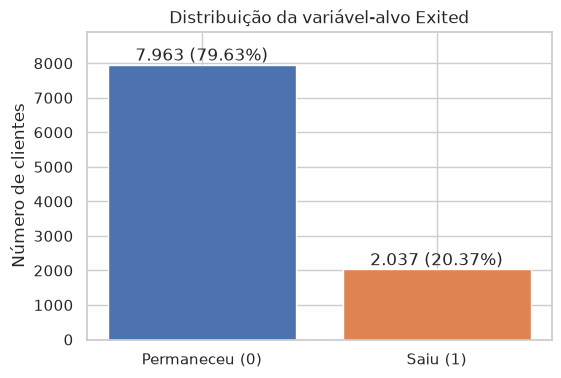

In [5]:
contagem = df["Exited"].value_counts().sort_index()
proporcao = df["Exited"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"clientes": contagem, "proporção": proporcao}).rename(index={0: "Permaneceu (0)", 1: "Saiu (1)"}))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Permaneceu (0)", "Saiu (1)"], contagem.values, color=["#4C72B0", "#DD8452"])
for b, n, p in zip(barras, contagem.values, proporcao.values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,} ({p:.2%})".replace(",", "."), ha="center", va="bottom")
ax.set_title("Distribuição da variável-alvo Exited")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, contagem.max() * 1.12)
plt.show()

**O que vimos:** **20,37%** dos clientes saíram do banco (2.037 de 10.000), o que confirma o "cerca de 20%" do enunciado. A classe positiva é minoritária (proporção de ~1 para 4). Consequência importante: um modelo que sempre previsse "não sai" já teria **79,63% de acurácia** sem aprender nada. Por isso vamos usar também AUC, precisão, *recall* e F1.

### 1.3 Taxa de *churn* por `Geography`, `Gender`, `IsActiveMember` e `NumOfProducts`

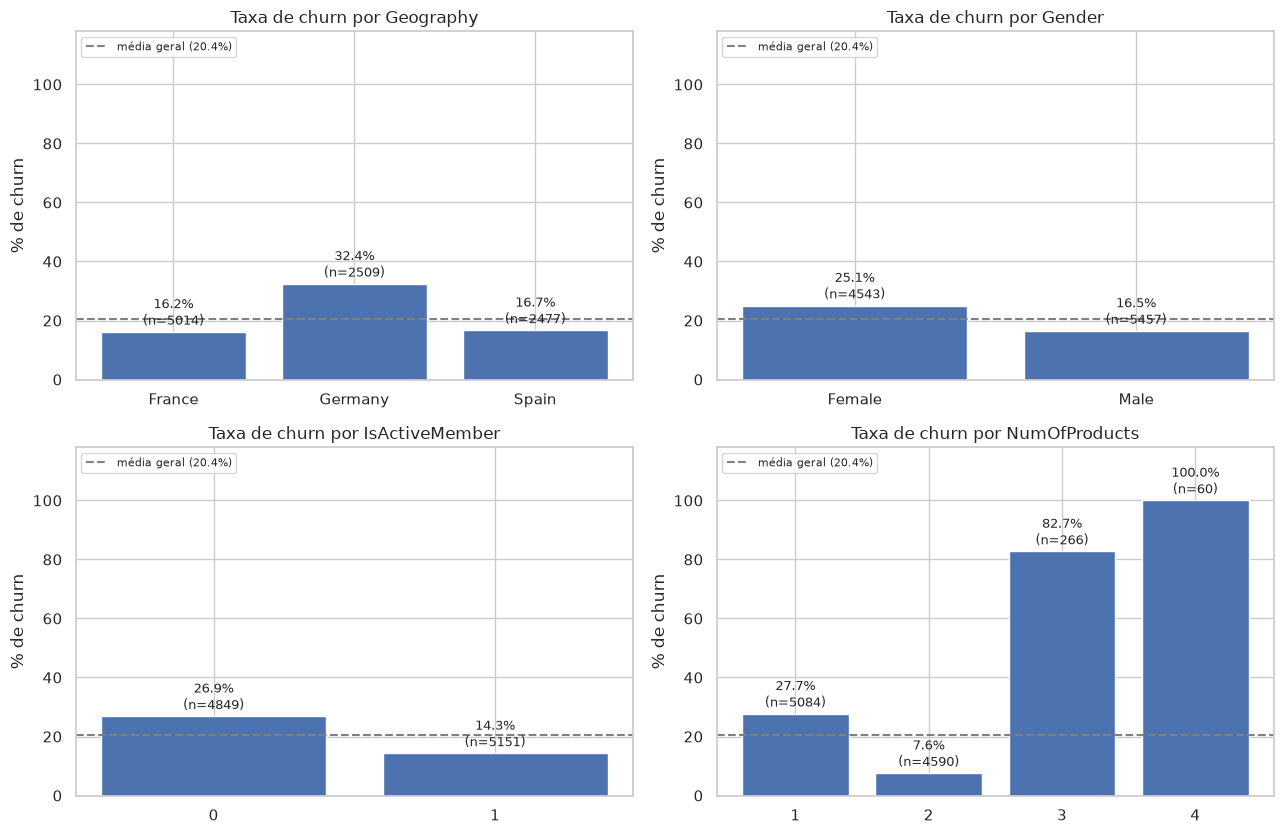

           taxa_churn  clientes
Geography                      
France         0.1615      5014
Germany        0.3244      2509
Spain          0.1667      2477 

        taxa_churn  clientes
Gender                      
Female      0.2507      4543
Male        0.1646      5457 

                taxa_churn  clientes
IsActiveMember                      
0                   0.2685      4849
1                   0.1427      5151 

               taxa_churn  clientes
NumOfProducts                      
1                  0.2771      5084
2                  0.0758      4590
3                  0.8271       266
4                  1.0000        60 



In [6]:
categoricas_eda = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
taxa_geral = df["Exited"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, col in zip(axes.flat, categoricas_eda):
    t = df.groupby(col)["Exited"].agg(taxa="mean", clientes="count")
    ax.bar(t.index.astype(str), t["taxa"] * 100, color="#4C72B0")
    ax.axhline(taxa_geral * 100, ls="--", color="gray", label=f"média geral ({taxa_geral:.1%})")
    for i, (taxa, n) in enumerate(zip(t["taxa"], t["clientes"])):
        ax.text(i, taxa * 100 + 1, f"{taxa:.1%}\n(n={n})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Taxa de churn por {col}")
    ax.set_ylabel("% de churn")
    ax.set_ylim(0, 118)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

for col in categoricas_eda:
    print(df.groupby(col)["Exited"].agg(taxa_churn="mean", clientes="count"), "\n")

**O que vimos:**
- **Geography:** a **Alemanha** tem taxa de churn de **~32%**, praticamente o dobro da França (~16%) e da Espanha (~17%).
- **Gender:** mulheres saem mais (**~25%**) que homens (**~16%**).
- **IsActiveMember:** clientes **inativos** saem quase duas vezes mais (**~27%**) que os ativos (**~14%**).
- **NumOfProducts:** a relação **não é linear**. Quem tem **2 produtos** quase não sai (**~8%**); quem tem 1 produto sai ~28%; e quem tem **3 ou 4 produtos** sai em massa (**~83%** e **100%**), embora sejam poucos clientes (266 e 60). Uma relação em "U" como essa é difícil para um modelo linear e é um bom motivo para testar uma rede neural.

### 1.4 Distribuições de `Age`, `Balance` e `CreditScore` por classe

Usamos densidade (e não contagem) para que as duas classes, que têm tamanhos diferentes, fiquem comparáveis no mesmo gráfico.

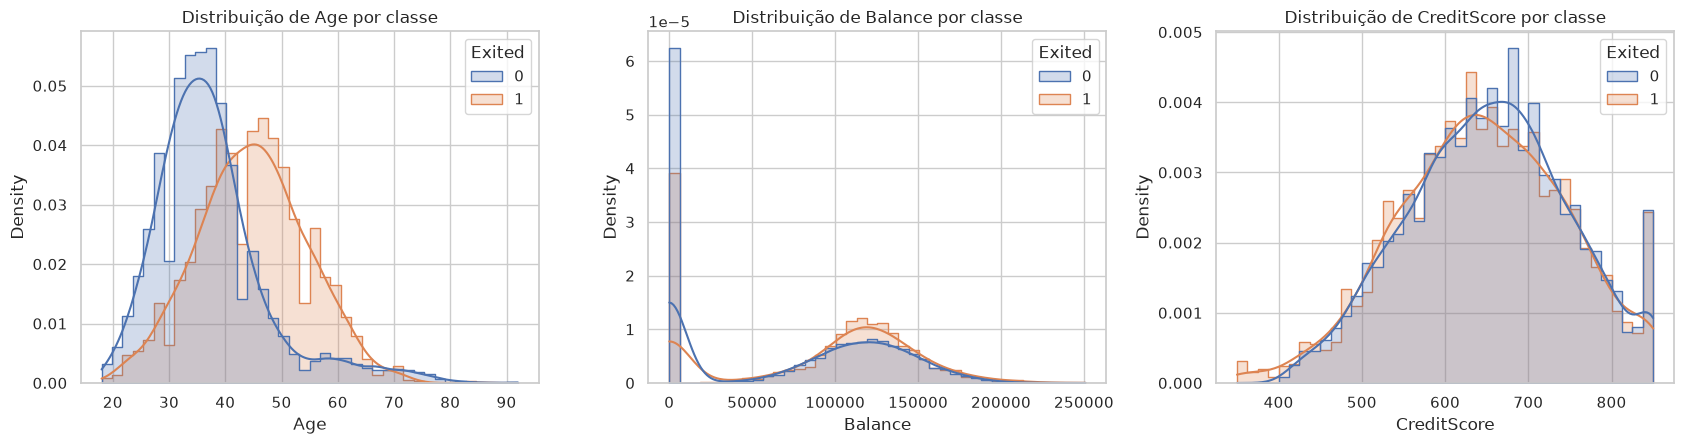

Medianas por classe (0 = permaneceu, 1 = saiu):
           Age     Balance  CreditScore  % com saldo zero
Exited                                                   
0      36.0000  92072.6800     653.0000           39.1435
1      45.0000 109349.2900     646.0000           24.5459


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col in zip(axes, ["Age", "Balance", "CreditScore"]):
    sns.histplot(data=df, x=col, hue="Exited", stat="density", common_norm=False, kde=True,
                 bins=40, element="step", palette={0: "#4C72B0", 1: "#DD8452"}, ax=ax)
    ax.set_title(f"Distribuição de {col} por classe")
plt.tight_layout()
plt.show()

resumo = df.groupby("Exited")[["Age", "Balance", "CreditScore"]].median()
resumo["% com saldo zero"] = df.groupby("Exited")["Balance"].apply(lambda s: (s == 0).mean() * 100)
print("Medianas por classe (0 = permaneceu, 1 = saiu):")
print(resumo)

**O que vimos:**
- **Age** é a variável que mais separa as classes: quem sai tem idade mediana de **~45 anos**, contra **~36** de quem fica. O churn se concentra entre 40 e 60 anos.
- **Balance** tem um pico enorme em **zero** (~36% dos clientes). Entre os que saem, a proporção de saldo zero é menor, e a mediana do saldo é mais alta: clientes com dinheiro aplicado também saem.
- **CreditScore** tem distribuições quase iguais nas duas classes; sozinho, parece pouco informativo (há apenas uma pequena cauda de churn com score muito baixo).

### 1.5 Hipóteses sobre os fatores de *churn*

Com base na análise acima, formulamos três hipóteses, que vamos testar na Parte 6 com a importância dos atributos:

1. **H1 – Idade:** a idade é o fator mais importante. Clientes entre 40 e 60 anos têm muito mais chance de sair, talvez por estarem numa fase de vida com mais patrimônio e mais exigências, ou por serem disputados pela concorrência.
2. **H2 – Engajamento e número de produtos:** clientes **inativos** e clientes com **1 produto** (pouco vínculo) ou **3–4 produtos** (possível insatisfação com produtos empurrados) saem mais. Ter exatamente 2 produtos parece ser o ponto de maior retenção.
3. **H3 – Alemanha:** existe um fator específico do mercado alemão (concorrência, condições ou atendimento) que dobra a taxa de churn em relação à França e à Espanha.

---
## 2. Pré-processamento

### 2.1 Remoção de `RowNumber`, `CustomerId` e `Surname`

- **RowNumber:** é só a posição da linha no arquivo, sem nenhuma informação sobre o cliente.
- **CustomerId:** é um identificador arbitrário. Se fosse usado, o modelo poderia "decorar" IDs, sem nenhuma capacidade de generalizar para clientes novos.
- **Surname:** sobrenome não tem relação causal com sair do banco, tem milhares de valores diferentes (o que aumentaria muito a dimensão dos dados) e usá-lo poderia introduzir **viés discriminatório** (origem étnica ou familiar).

In [8]:
df_modelo = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
X = df_modelo.drop(columns="Exited")
y = df_modelo["Exited"].to_numpy()
print("Atributos de entrada:", list(X.columns))
print("Formato de X:", X.shape)

Atributos de entrada: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Formato de X: (10000, 10)


### 2.2 Codificação de `Gender` e `Geography`

- **Gender** tem só duas categorias, então vira **uma única coluna binária** (`Male` = 1, `Female` = 0).
- **Geography** vira **one-hot**: uma coluna 0/1 para cada país (`France`, `Germany`, `Spain`).

**Por que não usar codificação ordinal em `Geography`?** Codificar França = 0, Espanha = 1, Alemanha = 2 diria ao modelo que existe uma **ordem** e uma **distância** entre os países (que a Alemanha é "duas vezes" a Espanha, ou que a Espanha fica "entre" a França e a Alemanha). Isso não faz sentido para países. O modelo poderia aprender relações falsas a partir desses números. Com one-hot, cada país é tratado como uma categoria independente.

As colunas `HasCrCard` e `IsActiveMember` já são 0/1, então passam sem alteração.

### 2.3 Divisão treino / validação / teste (70% / 15% / 15%)

A divisão é **estratificada** pela variável `Exited`, para que os três conjuntos tenham a mesma proporção de churn (~20,4%). Fazemos em dois passos: primeiro separamos 70% para treino; depois dividimos os 30% restantes ao meio. **O conjunto de teste fica guardado e só será usado uma vez, na Parte 5.3.**

In [9]:
X_treino_raw, X_temp_raw, y_treino, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val_raw, X_teste_raw, y_val, y_teste = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for nome, yy in [("Treino", y_treino), ("Validação", y_val), ("Teste", y_teste)]:
    print(f"{nome:10s}: {len(yy):5d} clientes ({len(yy)/len(y):.0%}) | churn = {yy.mean():.2%}")

Treino    :  7000 clientes (70%) | churn = 20.37%
Validação :  1500 clientes (15%) | churn = 20.40%
Teste     :  1500 clientes (15%) | churn = 20.33%


### 2.4 Padronização com `StandardScaler` e `ColumnTransformer`

Montamos todo o pré-processamento num `ColumnTransformer` e fazemos o **`fit` apenas no treino**. Validação e teste são só **transformados** com as médias e desvios do treino. Se o `fit` usasse os dados de validação ou teste, informações deles "vazariam" para o modelo e as métricas ficariam otimistas demais (**vazamento de dados**).

**Por que redes neurais precisam de escalonamento?** A rede combina as entradas com pesos (`w·x + b`) e aprende por gradiente descendente.
- Se `Balance` vai até 250.000 e `Tenure` até 10, os gradientes em relação aos pesos de `Balance` ficam milhares de vezes maiores. O treino fica instável ou muito lento, porque uma única taxa de aprendizado não serve bem para todos os pesos.
- Valores muito grandes também **saturam** ativações como tanh e sigmoide (a derivada fica perto de zero e a rede para de aprender).
- A inicialização dos pesos assume entradas em torno de 0 com variância perto de 1.

Com `StandardScaler`, cada variável numérica passa a ter média 0 e desvio padrão 1 (no treino).

In [10]:
colunas_numericas = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
colunas_binarias = ["HasCrCard", "IsActiveMember"]

preprocessador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), colunas_numericas),
        ("geo", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Geography"]),
        ("gen", OneHotEncoder(drop="if_binary", sparse_output=False), ["Gender"]),
        ("bin", "passthrough", colunas_binarias),
    ],
    verbose_feature_names_out=False,
)

X_treino = preprocessador.fit_transform(X_treino_raw).astype(np.float32)   # fit SÓ no treino
X_val = preprocessador.transform(X_val_raw).astype(np.float32)
X_teste = preprocessador.transform(X_teste_raw).astype(np.float32)
nomes_atributos = list(preprocessador.get_feature_names_out())
N_ENTRADAS = X_treino.shape[1]

print(f"Número de atributos após o pré-processamento: {N_ENTRADAS}")
print(nomes_atributos)

# Conferência: média ~0 e desvio ~1 no treino; na validação, perto disso mas não exato (prova de que não houve fit nela)
conf = pd.DataFrame({
    "média treino": X_treino[:, :6].mean(0), "desvio treino": X_treino[:, :6].std(0),
    "média validação": X_val[:, :6].mean(0), "desvio validação": X_val[:, :6].std(0),
}, index=colunas_numericas)
conf

Número de atributos após o pré-processamento: 12
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'HasCrCard', 'IsActiveMember']


,média treino,desvio treino,média validação,desvio validação
CreditScore,-0.0000,1.0000,-0.0023,1.0069
Age,-0.0000,1.0000,-0.0234,0.9688
Tenure,-0.0000,1.0000,0.0508,0.9765
Balance,-0.0000,1.0000,-0.0037,1.0034
NumOfProducts,-0.0000,1.0000,-0.0200,0.9768
EstimatedSalary,0.0000,1.0000,0.0435,0.9996


**O que vimos:** depois do pré-processamento temos **12 atributos** (6 numéricos padronizados, 3 colunas de país, 1 de gênero e 2 binárias). No treino, as médias são exatamente 0 e os desvios exatamente 1. Na validação, os valores ficam próximos, mas não idênticos, o que confirma que o `StandardScaler` foi ajustado **só no treino**.

---
## 3. Modelo de referência e primeira rede neural

### 3.1 Baseline: Regressão Logística

Antes da rede neural, treinamos uma **Regressão Logística**, um modelo linear simples. Ela serve de referência: a rede neural só vale a pena se for melhor que isso. A função abaixo calcula as métricas que vamos usar em todo o notebook.

In [11]:
def metricas(y_true, prob, limiar=0.5):
    # Métricas de classificação binária a partir das probabilidades previstas.
    pred = (prob >= limiar).astype(int)
    return {
        "acurácia": accuracy_score(y_true, pred),
        "precisão": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
    }

reg_log = LogisticRegression(max_iter=1000, random_state=SEED)
reg_log.fit(X_treino, y_treino)
prob_val_rl = reg_log.predict_proba(X_val)[:, 1]

resultados_val = {"Regressão Logística": metricas(y_val, prob_val_rl)}
pd.DataFrame(resultados_val).T

,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC
Regressão Logística,0.8100,0.6105,0.1895,0.2893,0.7847,0.5070


**O que vimos:** a Regressão Logística tem acurácia de ~81%, só um pouco acima dos 79,6% de "sempre prever que não sai", e um **recall baixo** (perto de 20%): com limiar de 0,5 ela encontra só uma pequena parte dos clientes que realmente saem. O ROC-AUC de ~0,78 mostra que ela ordena razoavelmente os clientes por risco, mas é linear e não consegue capturar efeitos como o "U" de `NumOfProducts`.

### 3.2 A MLP nos dois frameworks

Arquitetura pedida:
- **entrada** com 12 atributos;
- **duas camadas ocultas** com 16 neurônios e **ReLU**;
- **saída** com 1 neurônio e **sigmoide** (a probabilidade de churn).

As duas classes abaixo (`MLPTorch` e `MLPMLX`) aceitam qualquer número de camadas, ativação, *dropout* e uma camada de **normalização** opcional (**BatchNorm** ou **LayerNorm**), o que vamos usar na Parte 4. Cada camada oculta fica na ordem `Linear → normalização (opcional) → ativação → Dropout (opcional)`.

- **BatchNorm** padroniza cada neurônio usando a média e a variância **do lote** durante o treino. Ele também guarda médias "móveis" dessas estatísticas, que são usadas na previsão (modo `eval`).
- **LayerNorm** padroniza as ativações **de cada exemplo** em relação aos outros neurônios da mesma camada. Não depende do lote, então se comporta igual no treino e na previsão.

As duas têm dois parâmetros treináveis por neurônio (escala γ e deslocamento β), que podem "desfazer" a normalização se isso for útil para a rede.

**Detalhe de implementação:** a saída tem sigmoide (`forward`/`__call__` devolve a probabilidade). Para o **treino**, porém, usamos o método `logits` (a saída **antes** da sigmoide) junto com a *binary cross-entropy* "com logits". Matematicamente é **a mesma perda** que sigmoide + `binary_crossentropy`, mas é numericamente mais estável (evita `log(0)` quando a sigmoide satura). É o mesmo que o Keras faz internamente.

**Regularização L2:** somamos `λ · Σ w²` à perda, usando só os pesos das camadas `Linear` (não os vieses nem os parâmetros das normalizações), como o `kernel_regularizer=l2(λ)` do Keras. Implementamos à mão nos dois frameworks para que ela seja idêntica. O efeito é o mesmo de um *weight decay*: λ = 0,001 equivale a `torch.optim.Adam(weight_decay=0.002)`.

In [12]:
ATIVACOES_TORCH = {"relu": tnn.ReLU, "tanh": tnn.Tanh, "leaky_relu": lambda: tnn.LeakyReLU(0.01)}
ATIVACOES_MLX = {"relu": mnn.ReLU, "tanh": mnn.Tanh, "leaky_relu": lambda: mnn.LeakyReLU(0.01)}
NORMALIZACOES_TORCH = {"batch": tnn.BatchNorm1d, "layer": tnn.LayerNorm}
NORMALIZACOES_MLX = {"batch": mnn.BatchNorm, "layer": mnn.LayerNorm}


class MLPTorch(tnn.Module):
    def __init__(self, n_entradas, ocultas=(16, 16), ativacao="relu", dropout=0.0, norm=None):
        super().__init__()
        camadas, n = [], n_entradas
        for h in ocultas:
            camadas.append(tnn.Linear(n, h))
            if norm:
                camadas.append(NORMALIZACOES_TORCH[norm](h))
            camadas.append(ATIVACOES_TORCH[ativacao]())
            if dropout > 0:
                camadas.append(tnn.Dropout(dropout))
            n = h
        self.ocultas = tnn.Sequential(*camadas)
        self.saida = tnn.Linear(n, 1)

    def logits(self, x):
        return self.saida(self.ocultas(x)).squeeze(-1)

    def forward(self, x):                      # saída com sigmoide = probabilidade de churn
        return torch.sigmoid(self.logits(x))


class MLPMLX(mnn.Module):
    def __init__(self, n_entradas, ocultas=(16, 16), ativacao="relu", dropout=0.0, norm=None):
        super().__init__()
        camadas, n = [], n_entradas
        for h in ocultas:
            camadas.append(mnn.Linear(n, h))
            if norm:
                camadas.append(NORMALIZACOES_MLX[norm](h))
            camadas.append(ATIVACOES_MLX[ativacao]())
            if dropout > 0:
                camadas.append(mnn.Dropout(dropout))
            n = h
        self.ocultas = mnn.Sequential(*camadas)
        self.saida = mnn.Linear(n, 1)

    def logits(self, x):
        return self.saida(self.ocultas(x)).squeeze(-1)

    def __call__(self, x):                     # saída com sigmoide = probabilidade de churn
        return mx.sigmoid(self.logits(x))

**Adaptadores e laço de treino comum.** Para garantir uma comparação justa, cada framework ganha um pequeno "adaptador" com as mesmas operações (treinar um lote, prever, copiar e restaurar pesos). O **laço de treino é um só** (`treinar`), e ele faz o mesmo que o `model.fit` do Keras:
- embaralha o treino a cada época (com a mesma semente nos dois frameworks) e treina com **Adam** em lotes de `batch_size`;
- ao fim de cada época, registra **perda, acurácia e AUC** no treino e na validação;
- aceita **`pesos_classe`** (equivalente ao `class_weight` do Keras: cada exemplo é multiplicado pelo peso da sua classe na perda);
- implementa **Early Stopping** monitorando a perda de validação, com paciência configurável e **`restore_best_weights=True`** (volta aos pesos da melhor época).

No MLX, o passo de treino é **compilado** com `mx.compile`, que funde as operações num único grafo otimizado (ver Parte 7).

In [13]:
def penalidade_l2_torch(modelo):   # só os pesos das camadas Linear
    return sum((m.weight ** 2).sum() for m in modelo.modules() if isinstance(m, tnn.Linear))

def penalidade_l2_mlx(modelo):     # só os pesos das camadas Linear
    return sum((m.weight ** 2).sum() for m in modelo.modules() if isinstance(m, mnn.Linear))


class AdaptadorTorch:
    nome = "PyTorch"

    def __init__(self, cfg, n_entradas):
        self.cfg = cfg
        self.modelo = MLPTorch(n_entradas, cfg["ocultas"], cfg["ativacao"], cfg.get("dropout", 0.0), cfg.get("norm"))
        self.otimizador = torch.optim.Adam(self.modelo.parameters(), lr=cfg["lr"])

    def preparar(self, X, y, w):
        self.X, self.y, self.w = (torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)) for a in (X, y, w))

    def treinar_lote(self, idx):
        self.modelo.train()
        i = torch.from_numpy(idx)
        self.otimizador.zero_grad()
        perda = TF.binary_cross_entropy_with_logits(self.modelo.logits(self.X[i]), self.y[i], reduction="none")
        perda = (perda * self.w[i]).mean()
        if self.cfg.get("l2", 0) > 0:
            perda = perda + self.cfg["l2"] * penalidade_l2_torch(self.modelo)
        perda.backward()
        self.otimizador.step()

    def prever(self, X):
        self.modelo.eval()
        with torch.no_grad():
            return self.modelo(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy()

    def copiar_pesos(self):
        return {k: v.detach().clone() for k, v in self.modelo.state_dict().items()}

    def restaurar_pesos(self, pesos):
        self.modelo.load_state_dict(pesos)

    def n_parametros(self):
        return sum(p.numel() for p in self.modelo.parameters() if p.requires_grad)

    def salvar(self, caminho):
        torch.save(self.modelo.state_dict(), caminho)


class AdaptadorMLX:
    nome = "MLX"

    def __init__(self, cfg, n_entradas, compilar=True):
        self.cfg = cfg
        self.modelo = MLPMLX(n_entradas, cfg["ocultas"], cfg["ativacao"], cfg.get("dropout", 0.0), cfg.get("norm"))
        mx.eval(self.modelo.parameters())
        self.otimizador = mopt.Adam(learning_rate=cfg["lr"])
        l2 = cfg.get("l2", 0.0)

        def funcao_perda(modelo, x, y, w):
            perda = mnn.losses.binary_cross_entropy(modelo.logits(x), y, with_logits=True, reduction="none")
            perda = (perda * w).mean()
            if l2 > 0:
                perda = perda + l2 * penalidade_l2_mlx(modelo)
            return perda

        perda_e_grad = mnn.value_and_grad(self.modelo, funcao_perda)

        def passo(x, y, w):
            perda, grads = perda_e_grad(self.modelo, x, y, w)
            self.otimizador.update(self.modelo, grads)
            return perda

        if compilar:
            # o estado (pesos, otimizador e gerador aleatório do dropout) entra e sai da função compilada
            estado = [self.modelo.state, self.otimizador.state, mx.random.state]
            passo = partial(mx.compile, inputs=estado, outputs=estado)(passo)
            self._estado = estado
        self._passo = passo

    def preparar(self, X, y, w):
        self.X, self.y, self.w = (mx.array(np.asarray(a, dtype=np.float32)) for a in (X, y, w))

    def treinar_lote(self, idx):
        self.modelo.train()
        i = mx.array(idx)
        self._passo(self.X[i], self.y[i], self.w[i])
        mx.eval(self.modelo.state, self.otimizador.state)

    def prever(self, X):
        self.modelo.eval()
        p = self.modelo(mx.array(np.asarray(X, dtype=np.float32)))
        return np.array(p)

    def copiar_pesos(self):
        return {k: mx.array(v) for k, v in tree_flatten(self.modelo.parameters())}

    def restaurar_pesos(self, pesos):
        self.modelo.update(tree_unflatten(list(pesos.items())))
        mx.eval(self.modelo.parameters())

    def n_parametros(self):
        return sum(v.size for _, v in tree_flatten(self.modelo.trainable_parameters()))

    def salvar(self, caminho):
        self.modelo.save_weights(caminho)


FRAMEWORKS = {"PyTorch": AdaptadorTorch, "MLX": AdaptadorMLX}


def perda_bce(y_true, prob):
    p = np.clip(prob, 1e-7, 1 - 1e-7)
    return float(-np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))


def treinar(framework, cfg, X_tr, y_tr, X_va, y_va, epocas=100, batch_size=32,
            early_stopping=False, paciencia=15, pesos_classe=None, seed=SEED):
    # Laço de treino comum aos dois frameworks (equivalente ao model.fit do Keras).
    fixar_sementes(seed)
    adaptador = FRAMEWORKS[framework](cfg, X_tr.shape[1])
    w = np.ones(len(y_tr), dtype=np.float32) if pesos_classe is None else \
        np.where(y_tr == 1, pesos_classe[1], pesos_classe[0]).astype(np.float32)
    adaptador.preparar(X_tr, y_tr, w)
    rng = np.random.default_rng(seed)
    hist = {k: [] for k in ["loss", "val_loss", "acc", "val_acc", "auc", "val_auc"]}
    melhor_perda, melhor_epoca, melhores_pesos, sem_melhora = np.inf, 0, None, 0

    inicio = time.perf_counter()
    for epoca in range(1, epocas + 1):
        ordem = rng.permutation(len(y_tr))
        for i in range(0, len(ordem), batch_size):
            adaptador.treinar_lote(ordem[i:i + batch_size])

        p_tr, p_va = adaptador.prever(X_tr), adaptador.prever(X_va)
        hist["loss"].append(perda_bce(y_tr, p_tr));  hist["val_loss"].append(perda_bce(y_va, p_va))
        hist["acc"].append(accuracy_score(y_tr, p_tr >= 0.5)); hist["val_acc"].append(accuracy_score(y_va, p_va >= 0.5))
        hist["auc"].append(roc_auc_score(y_tr, p_tr));  hist["val_auc"].append(roc_auc_score(y_va, p_va))

        if hist["val_loss"][-1] < melhor_perda:
            melhor_perda, melhor_epoca, sem_melhora = hist["val_loss"][-1], epoca, 0
            if early_stopping:
                melhores_pesos = adaptador.copiar_pesos()
        else:
            sem_melhora += 1
            if early_stopping and sem_melhora >= paciencia:
                break
    tempo = time.perf_counter() - inicio

    if early_stopping:
        adaptador.restaurar_pesos(melhores_pesos)   # restore_best_weights=True
    info = {"épocas treinadas": epoca, "melhor época": melhor_epoca, "tempo (s)": tempo}
    return adaptador, hist, info


def descrever(cfg):
    camadas = "-".join(map(str, cfg["ocultas"]))
    norm = {"batch": " | BatchNorm", "layer": " | LayerNorm"}.get(cfg.get("norm"), "")
    return (f"{len(cfg['ocultas'])}x[{camadas}] {cfg['ativacao']} | lr={cfg['lr']:g} | "
            f"dropout={cfg.get('dropout', 0):g} | L2={cfg.get('l2', 0):g}{norm}")

### 3.3 Treino da MLP inicial: 100 épocas, `batch_size=32`, Adam, *binary cross-entropy*

Treinamos a arquitetura pedida (16-16, ReLU, Adam com taxa de aprendizado padrão 0,001), **sem regularização e sem Early Stopping**, para observar o comportamento natural da rede. Em cada época registramos acurácia e AUC no treino e na validação.

In [14]:
CFG_INICIAL = {"ocultas": (16, 16), "ativacao": "relu", "lr": 1e-3, "dropout": 0.0, "l2": 0.0}

modelos_iniciais, historicos_iniciais = {}, {}
for fw in FRAMEWORKS:
    adaptador, hist, info = treinar(fw, CFG_INICIAL, X_treino, y_treino, X_val, y_val, epocas=100, batch_size=32)
    modelos_iniciais[fw], historicos_iniciais[fw] = adaptador, hist
    resultados_val[f"MLP inicial ({fw})"] = metricas(y_val, adaptador.prever(X_val))
    print(f"{fw:8s}: {info['tempo (s)']:.1f} s | menor perda de validação na época {info['melhor época']}")

pd.DataFrame(resultados_val).T

PyTorch : 15.6 s | menor perda de validação na época 39


MLX     : 16.7 s | menor perda de validação na época 79


,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC
Regressão Logística,0.8100,0.6105,0.1895,0.2893,0.7847,0.5070
MLP inicial (PyTorch),0.8660,0.7465,0.5196,0.6127,0.8779,0.7186
MLP inicial (MLX),0.8627,0.7193,0.5359,0.6142,0.8726,0.7105


### 3.4 Curvas de perda e de AUC (treino × validação)

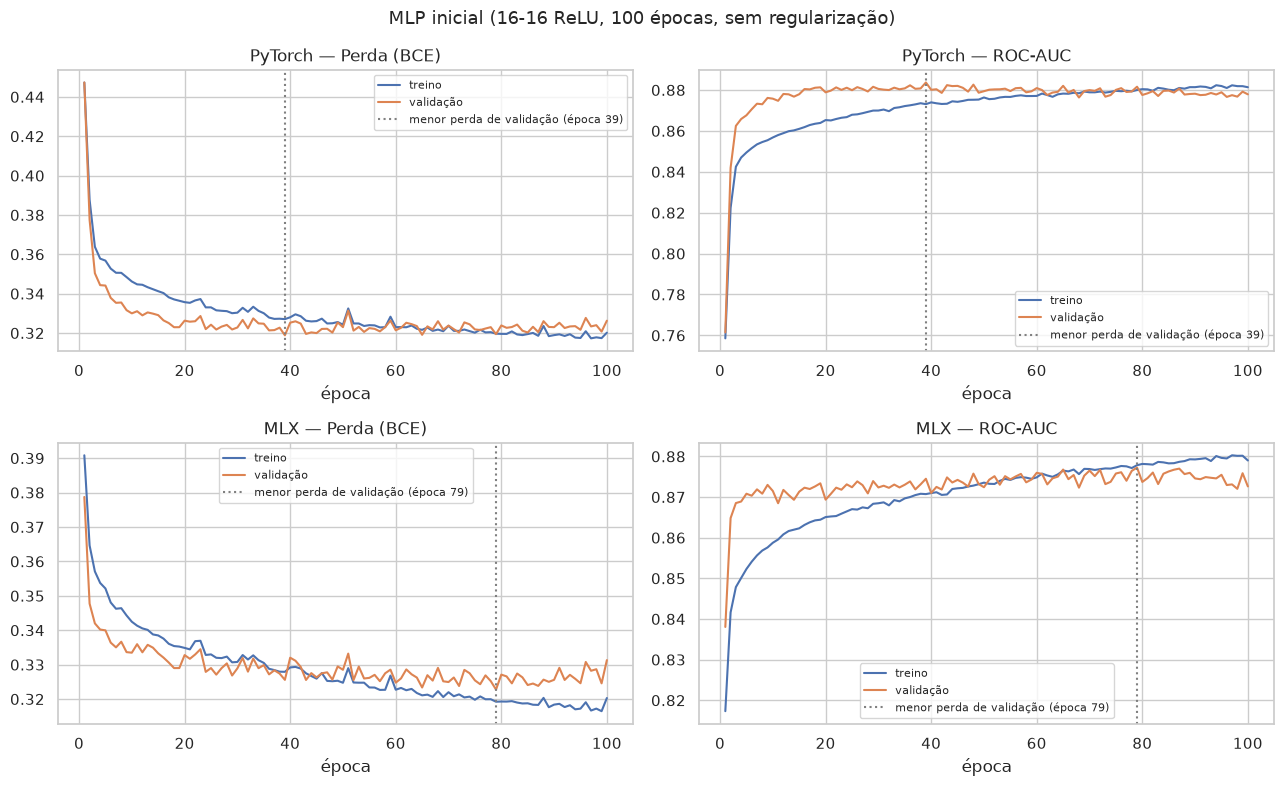

PyTorch : menor perda de validação 0.3188 na época 39; na época 100: treino 0.3202 × validação 0.3263 (AUC treino 0.8814 × validação 0.8779)
MLX     : menor perda de validação 0.3228 na época 79; na época 100: treino 0.3203 × validação 0.3313 (AUC treino 0.8790 × validação 0.8726)


In [15]:
def plotar_curvas(historicos, titulo, marcar=None):
    fig, axes = plt.subplots(len(historicos), 2, figsize=(13, 4 * len(historicos)), squeeze=False)
    for linha, (fw, h) in enumerate(historicos.items()):
        ep = np.arange(1, len(h["loss"]) + 1)
        for col, (chave, nome) in enumerate([("loss", "Perda (BCE)"), ("auc", "ROC-AUC")]):
            ax = axes[linha, col]
            ax.plot(ep, h[chave], label="treino")
            ax.plot(ep, h["val_" + chave], label="validação")
            melhor = int(np.argmin(h["val_loss"])) + 1
            ax.axvline(melhor, ls=":", color="gray", label=f"menor perda de validação (época {melhor})")
            ax.set_title(f"{fw} — {nome}")
            ax.set_xlabel("época")
            ax.legend(fontsize=8)
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

plotar_curvas(historicos_iniciais, "MLP inicial (16-16 ReLU, 100 épocas, sem regularização)")

for fw, h in historicos_iniciais.items():
    m = int(np.argmin(h["val_loss"]))
    print(f"{fw:8s}: menor perda de validação {h['val_loss'][m]:.4f} na época {m+1}; "
          f"na época 100: treino {h['loss'][-1]:.4f} × validação {h['val_loss'][-1]:.4f} "
          f"(AUC treino {h['auc'][-1]:.4f} × validação {h['val_auc'][-1]:.4f})")

**Há *overfitting*?** Sim, mas **leve**, e ele aparece do mesmo jeito nos dois frameworks:
- a **perda de treino continua caindo** até a época 100;
- a **perda de validação** cai nas primeiras dezenas de épocas, atinge o mínimo (linha pontilhada) e depois **para de melhorar** (e tende a subir devagar), ficando acima da perda de treino;
- com a AUC acontece o mesmo: ela continua subindo no treino, mas estabiliza na validação.

Ou seja, depois do mínimo a rede passa a **decorar particularidades do treino** em vez de aprender padrões gerais. O efeito é pequeno (a diferença entre as perdas de treino e validação fica na casa de centésimos), porque a rede é pequena (497 parâmetros) para 7.000 exemplos. Ainda assim, treinar além do mínimo não traz nenhum ganho, o que justifica o uso de **Early Stopping** e regularização na Parte 4.

Mesmo sem ajustes, a MLP já supera bastante a Regressão Logística na validação (ROC-AUC de ~0,87–0,88 contra ~0,78), o que indica que existem relações não lineares que o modelo linear não captura.

### 3.5 Número de parâmetros treináveis

Uma camada densa (`Linear`) com `n` entradas e `m` neurônios tem uma matriz de pesos `n × m` e um viés por neurônio, ou seja, **`n × m + m`** parâmetros.

**Primeira camada oculta:** 12 entradas × 16 neurônios = 192 pesos, **mais 16 vieses = 208 parâmetros**.

| Camada | Cálculo | Parâmetros |
|---|---|---|
| Oculta 1 (12 → 16) | 12 × 16 + 16 | 208 |
| Oculta 2 (16 → 16) | 16 × 16 + 16 | 272 |
| Saída (16 → 1) | 16 × 1 + 1 | 17 |
| **Total** | | **497** |

As ativações (ReLU, sigmoide) não têm parâmetros. A célula abaixo confere a conta nos dois frameworks.

In [16]:
def contar_por_camada(ocultas, n_entradas):
    tamanhos = [n_entradas, *ocultas, 1]
    return [(f"{a} → {b}", a * b + b) for a, b in zip(tamanhos[:-1], tamanhos[1:])]

for camada, n in contar_por_camada(CFG_INICIAL["ocultas"], N_ENTRADAS):
    print(f"  camada {camada:8s}: {n:4d} parâmetros")
total_formula = sum(n for _, n in contar_por_camada(CFG_INICIAL["ocultas"], N_ENTRADAS))
print(f"  total pela fórmula: {total_formula}")
for fw, ad in modelos_iniciais.items():
    print(f"  total contado no {fw}: {ad.n_parametros()}")
assert all(ad.n_parametros() == total_formula for ad in modelos_iniciais.values())

  camada 12 → 16 :  208 parâmetros
  camada 16 → 16 :  272 parâmetros
  camada 16 → 1  :   17 parâmetros
  total pela fórmula: 497
  total contado no PyTorch: 497
  total contado no MLX: 497


---
## 4. Ajuste de hiperparâmetros e regularização

### 4.1 Configurações testadas

Testamos **12 configurações**, variando:
- número de camadas ocultas (1 a 3) e neurônios por camada (8 a 128);
- função de ativação (ReLU, tanh, LeakyReLU);
- taxa de aprendizado (0,01; 0,001; 0,0001);
- *Dropout* (0 a 0,5) e regularização L2;
- normalização: as configurações 11 e 12 são **iguais à 4**, acrescentando **BatchNorm** e **LayerNorm**, respectivamente. Assim, a comparação com a 4 mostra o efeito isolado de cada normalização.

Todas são treinadas com **Early Stopping** monitorando a **perda de validação**, paciência de 15 épocas e `restore_best_weights=True` (o modelo final de cada configuração é o da melhor época). O limite é de 300 épocas, para que a configuração com taxa de aprendizado 0,0001 (que aprende mais devagar) tenha tempo de convergir.

Cada configuração é treinada **nos dois frameworks**. O F1 é calculado com o limiar padrão de 0,5.

In [17]:
CONFIGS = [
    {"ocultas": (16, 16),      "ativacao": "relu",       "lr": 1e-3, "dropout": 0.0, "l2": 0.0},   # 1: arquitetura inicial + ES
    {"ocultas": (8,),          "ativacao": "relu",       "lr": 1e-3, "dropout": 0.0, "l2": 0.0},   # 2: rede mínima
    {"ocultas": (32, 16),      "ativacao": "tanh",       "lr": 1e-3, "dropout": 0.2, "l2": 0.0},   # 3: tanh
    {"ocultas": (64, 32),      "ativacao": "relu",       "lr": 1e-3, "dropout": 0.3, "l2": 0.0},   # 4: mais larga + dropout
    {"ocultas": (64, 32),      "ativacao": "leaky_relu", "lr": 1e-3, "dropout": 0.2, "l2": 1e-4},  # 5: LeakyReLU + L2
    {"ocultas": (64, 64, 32),  "ativacao": "relu",       "lr": 1e-3, "dropout": 0.3, "l2": 1e-4},  # 6: 3 camadas
    {"ocultas": (128, 64),     "ativacao": "relu",       "lr": 1e-2, "dropout": 0.5, "l2": 0.0},   # 7: lr alta + dropout forte
    {"ocultas": (64, 32),      "ativacao": "relu",       "lr": 1e-4, "dropout": 0.2, "l2": 0.0},   # 8: lr baixa
    {"ocultas": (128, 64, 32), "ativacao": "leaky_relu", "lr": 1e-3, "dropout": 0.4, "l2": 1e-3},  # 9: grande + regularização forte
    {"ocultas": (32, 32),      "ativacao": "relu",       "lr": 1e-3, "dropout": 0.1, "l2": 1e-4},  # 10: média + regularização leve
    {"ocultas": (64, 32),      "ativacao": "relu",       "lr": 1e-3, "dropout": 0.3, "l2": 0.0, "norm": "batch"},  # 11: = #4 + BatchNorm
    {"ocultas": (64, 32),      "ativacao": "relu",       "lr": 1e-3, "dropout": 0.3, "l2": 0.0, "norm": "layer"},  # 12: = #4 + LayerNorm
]

linhas, historicos_busca, modelos_busca = [], {}, {}
for i, cfg in enumerate(CONFIGS, start=1):
    linha = {"#": i, "configuração": descrever(cfg)}
    for fw in FRAMEWORKS:
        ad, hist, info = treinar(fw, cfg, X_treino, y_treino, X_val, y_val,
                                 epocas=300, early_stopping=True, paciencia=15)
        p = ad.prever(X_val)
        m = metricas(y_val, p)
        linha[f"épocas ({fw})"] = f"{info['melhor época']}/{info['épocas treinadas']}"
        linha[f"AUC val ({fw})"] = m["ROC-AUC"]
        linha[f"F1 val ({fw})"] = m["F1"]
        historicos_busca[(i, fw)], modelos_busca[(i, fw)] = hist, ad
    linha["AUC val (média)"] = (linha["AUC val (PyTorch)"] + linha["AUC val (MLX)"]) / 2
    linha["F1 val (média)"] = (linha["F1 val (PyTorch)"] + linha["F1 val (MLX)"]) / 2
    linhas.append(linha)
    print(f"[{i:2d}] {linha['configuração']:60s} AUC média = {linha['AUC val (média)']:.4f}")

tabela_busca = pd.DataFrame(linhas).set_index("#")

[ 1] 2x[16-16] relu | lr=0.001 | dropout=0 | L2=0                 AUC média = 0.8805


[ 2] 1x[8] relu | lr=0.001 | dropout=0 | L2=0                     AUC média = 0.8802


[ 3] 2x[32-16] tanh | lr=0.001 | dropout=0.2 | L2=0               AUC média = 0.8860


[ 4] 2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0               AUC média = 0.8829


[ 5] 2x[64-32] leaky_relu | lr=0.001 | dropout=0.2 | L2=0.0001    AUC média = 0.8864


[ 6] 3x[64-64-32] relu | lr=0.001 | dropout=0.3 | L2=0.0001       AUC média = 0.8850


... (2 outputs left out)

[ 9] 3x[128-64-32] leaky_relu | lr=0.001 | dropout=0.4 | L2=0.001 AUC média = 0.8888


[10] 2x[32-32] relu | lr=0.001 | dropout=0.1 | L2=0.0001          AUC média = 0.8815


[11] 2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0 | BatchNorm   AUC média = 0.8836


[12] 2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0 | LayerNorm   AUC média = 0.8827


### 4.2 Tabela de resultados (validação)

A coluna "épocas" mostra `melhor época / épocas treinadas`: o Early Stopping parou o treino 15 épocas depois da melhor, e os pesos da melhor época foram restaurados.

In [18]:
tabela_busca.sort_values("AUC val (média)", ascending=False)

,configuração,épocas (PyTorch),AUC val (PyTorch),F1 val (PyTorch),épocas (MLX),AUC val (MLX),F1 val (MLX),AUC val (média),F1 val (média)
#,,,,,,,,,
9,3x[128-64-32] leaky_relu | lr=0.001 | dropout=...,44/59,0.8886,0.6118,45/60,0.8890,0.5988,0.8888,0.6053
5,2x[64-32] leaky_relu | lr=0.001 | dropout=0.2 ...,43/58,0.8864,0.6078,39/54,0.8863,0.6110,0.8864,0.6094
3,2x[32-16] tanh | lr=0.001 | dropout=0.2 | L2=0,117/132,0.8863,0.6094,99/114,0.8856,0.6145,0.8860,0.6119
6,3x[64-64-32] relu | lr=0.001 | dropout=0.3 | L...,24/39,0.8831,0.6151,52/67,0.8868,0.6262,0.8850,0.6207
11,2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0...,52/67,0.8840,0.6057,54/69,0.8833,0.6032,0.8836,0.6045
4,2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0,32/47,0.8840,0.6141,32/47,0.8818,0.6297,0.8829,0.6219
12,2x[64-32] relu | lr=0.001 | dropout=0.3 | L2=0...,43/58,0.8827,0.6145,24/39,0.8828,0.6068,0.8827,0.6106
8,2x[64-32] relu | lr=0.0001 | dropout=0.2 | L2=0,268/283,0.8828,0.5992,190/205,0.8815,0.6032,0.8821,0.6012
10,2x[32-32] relu | lr=0.001 | dropout=0.1 | L2=0...,39/54,0.8812,0.5904,18/33,0.8818,0.6004,0.8815,0.5954


### 4.3 Escolha do melhor modelo

**Critério:** escolhemos a configuração com **maior ROC-AUC média na validação** (média dos dois frameworks). Motivos:
- a AUC avalia a capacidade de **ordenar** os clientes por risco, **independentemente do limiar**. O F1 com limiar 0,5 ainda vai mudar quando ajustarmos o limiar na Parte 5, então ele não é um bom critério de escolha aqui;
- usar a **média dos dois frameworks** reduz o peso da sorte (inicialização aleatória) e garante que o PyTorch e o MLX usem **a mesma arquitetura** daqui em diante, mantendo a comparação justa;
- em caso de empate técnico (diferença menor que 0,002), preferimos o modelo mais simples (menos parâmetros), que tende a generalizar melhor.

Configurações empatadas tecnicamente com a melhor (AUC ≥ 0.8868): [9]

➡️ Melhor configuração: #9 — 3x[128-64-32] leaky_relu | lr=0.001 | dropout=0.4 | L2=0.001
   parâmetros: 12033 | AUC val média: 0.8888 | F1 val médio: 0.6053


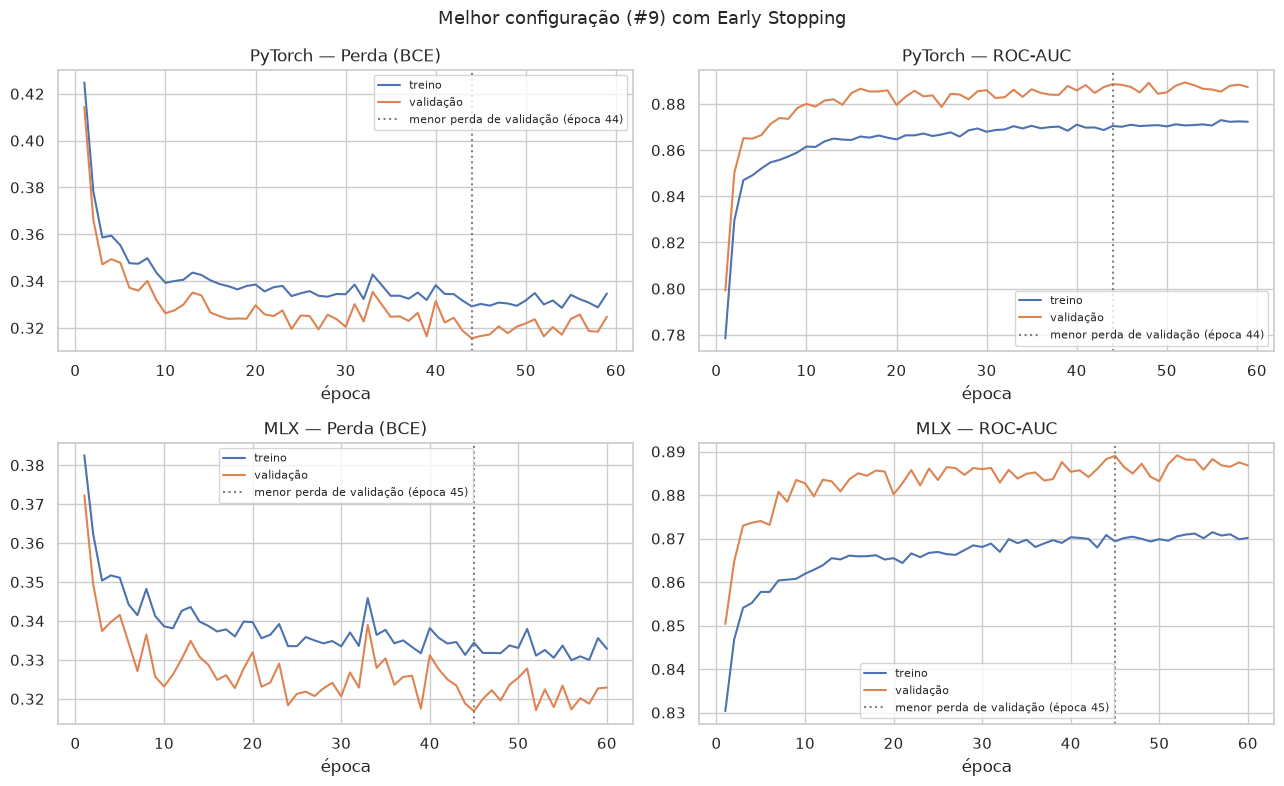

In [19]:
def n_params_cfg(cfg):   # camadas Linear + 2 parâmetros (γ, β) por neurônio se houver normalização
    extra = 2 * sum(cfg["ocultas"]) if cfg.get("norm") else 0
    return sum(n for _, n in contar_por_camada(cfg["ocultas"], N_ENTRADAS)) + extra

tabela_busca["parâmetros"] = [n_params_cfg(c) for c in CONFIGS]
melhor_auc = tabela_busca["AUC val (média)"].max()
empatados = tabela_busca[tabela_busca["AUC val (média)"] >= melhor_auc - 0.002]
ID_MELHOR = int(empatados.sort_values(["parâmetros", "AUC val (média)"], ascending=[True, False]).index[0])
CFG_MELHOR = CONFIGS[ID_MELHOR - 1]

print(f"Configurações empatadas tecnicamente com a melhor (AUC ≥ {melhor_auc - 0.002:.4f}): {list(empatados.index)}")
print(f"\n➡️ Melhor configuração: #{ID_MELHOR} — {descrever(CFG_MELHOR)}")
print(f"   parâmetros: {n_params_cfg(CFG_MELHOR)} | AUC val média: {tabela_busca.loc[ID_MELHOR, 'AUC val (média)']:.4f}"
      f" | F1 val médio: {tabela_busca.loc[ID_MELHOR, 'F1 val (média)']:.4f}")

plotar_curvas({fw: historicos_busca[(ID_MELHOR, fw)] for fw in FRAMEWORKS},
              f"Melhor configuração (#{ID_MELHOR}) com Early Stopping")

In [20]:
# Análise gerada a partir dos resultados: os números e as conclusões se ajustam a cada execução
tb = tabela_busca
auc, f1m, params = tb["AUC val (média)"], tb["F1 val (média)"], tb["parâmetros"]
ranking = auc.rank(ascending=False, method="min").astype(int)
n_cfg = len(tb)
melhor_ep = lambda i: np.mean([int(tb.loc[i, f"épocas ({fw})"].split("/")[0]) for fw in FRAMEWORKS])
ids_onde = lambda cond: [i for i, c in enumerate(CONFIGS, start=1) if cond(c)]
textos = ["**Análise:**"]

# Early Stopping
treinadas = [int(tb.loc[i, f"épocas ({fw})"].split("/")[1]) for i in tb.index for fw in FRAMEWORKS]
pararam = sum(t < 300 for t in treinadas)
if pararam == len(treinadas):
    es = "todas as configurações pararam antes do limite de 300 épocas, nos dois frameworks"
else:
    es = (f"{pararam} dos {len(treinadas)} treinos ({n_cfg} configurações × 2 frameworks) pararam antes do limite de 300 épocas; "
          "os demais usaram as 300 épocas, sinal de que ainda melhoravam devagar")
textos.append(f"- **Early Stopping** funcionou como esperado: {es}. As curvas da melhor configuração mostram que o treino termina "
              "perto do ponto em que a validação deixa de melhorar, sem o afastamento entre treino e validação visto na Parte 3.")

# Regularização
sem_reg = ids_onde(lambda c: c["dropout"] == 0 and c["l2"] == 0)
com_reg = [i for i in tb.index if i not in sem_reg]
a_sem, a_com = auc[sem_reg].max(), auc[com_reg].max()
if a_com >= a_sem:
    textos.append(f"- As configurações com **Dropout e/ou L2** chegam mais longe: a melhor delas tem AUC de {br(a_com)}, contra {br(a_sem)} "
                  "da melhor sem regularização, mesmo sendo redes maiores. A regularização permite usar mais neurônios sem *overfitting*.")
else:
    textos.append(f"- Nesta execução, a melhor configuração **sem regularização** (AUC {br(a_sem)}) ficou à frente da melhor com Dropout "
                  f"e/ou L2 ({br(a_com)}). Com redes pequenas e 7.000 exemplos, o *overfitting* já é pequeno e a regularização trouxe pouco ganho.")

# Taxa de aprendizado
ep_baixa = np.mean([melhor_ep(i) for i in ids_onde(lambda c: c["lr"] == 1e-4)])
ep_padrao = np.median([melhor_ep(i) for i in ids_onde(lambda c: c["lr"] == 1e-3)])
id_alta = ids_onde(lambda c: c["lr"] == 1e-2)[0]
pos_f1_alta = int(f1m.rank(ascending=False, method="min")[id_alta])
f1_alta = "teve o **pior F1** de todas" if pos_f1_alta == n_cfg else f"ficou na posição {pos_f1_alta} de {n_cfg} em F1"
textos.append(f"- A **taxa de aprendizado 0,0001** aprende muito devagar: a melhor época foi, em média, a {ep_baixa:.0f}ª, contra cerca "
              f"de {ep_padrao:.0f} nas configurações com 0,001. A **0,01** converge em poucas épocas (melhor época média: "
              f"{melhor_ep(id_alta):.0f}ª), mas seus passos grandes tornam o treino mais instável, e ela {f1_alta}.")

# Melhor configuração
regs = []
if CFG_MELHOR["dropout"] > 0:
    regs.append(f"Dropout {br(CFG_MELHOR['dropout'], 1)}")
if CFG_MELHOR["l2"] > 0:
    regs.append(f"L2 {CFG_MELHOR['l2']:g}".replace(".", ","))
p_melhor = params[ID_MELHOR]
grande = p_melhor >= params.median()
tamanho = ("a **maior rede testada**" if p_melhor == params.max() else
           "uma das **maiores redes testadas**" if grande else "uma rede **relativamente pequena**")
p_txt = f"{p_melhor:,}".replace(",", ".")
n_camadas = len(CFG_MELHOR["ocultas"])
camadas_txt = f"{n_camadas} camada oculta" if n_camadas == 1 else f"{n_camadas} camadas ocultas"
frase = (f"- A melhor configuração é a **#{ID_MELHOR}** ({camadas_txt}, "
         f"{p_txt} parâmetros), {tamanho}")
if regs and grande:
    frase += f", combinada com regularização ({' e '.join(regs)}). Isso mostra que capacidade extra só ajuda quando vem acompanhada de regularização."
elif regs:
    frase += f", com regularização ({' e '.join(regs)}). Nesta base, aumentar a rede não trouxe ganho."
else:
    frase += ", sem regularização."
outros = [i for i in empatados.index if i != ID_MELHOR]
if outros:
    lista = ", ".join("#" + str(i) for i in outros)
    frase += (f" A(s) configuração(ões) {lista} ficou(aram) tecnicamente empatada(s) com ela (diferença de AUC menor que 0,002); "
              "pelo critério de desempate, fiquei com a de menos parâmetros.")
textos.append(frase)

# Normalização
id_bn = ids_onde(lambda c: c.get("norm") == "batch")[0]
id_ln = ids_onde(lambda c: c.get("norm") == "layer")[0]
base_norm = {k: v for k, v in CONFIGS[id_bn - 1].items() if k != "norm"}
id_base = ids_onde(lambda c: c == base_norm)[0]
d_bn, d_ln = auc[id_bn] - auc[id_base], auc[id_ln] - auc[id_base]
sinal = lambda d: ("+" if d >= 0 else "−") + br(abs(d))
explicacao = ("As entradas já foram padronizadas pelo `StandardScaler` e a rede tem só 2 camadas ocultas. As normalizações ajudam mais "
              "em redes **profundas**, em que a escala das ativações vai se deformando de camada para camada e o treino fica instável.")
if max(abs(d_bn), abs(d_ln)) < 0.002:
    textos.append(f"- **BatchNorm e LayerNorm praticamente não fazem diferença** nesta base: comparadas com a configuração #{id_base} "
                  f"(idêntica, mas sem normalização), a AUC variou {sinal(d_bn)} e {sinal(d_ln)}, respectivamente, dentro do ruído "
                  f"causado pela inicialização aleatória. Isso é esperado: {explicacao[0].lower() + explicacao[1:]} Aqui esse problema "
                  "não existe, então elas só acrescentam parâmetros e custo computacional.")
else:
    efeito = lambda d: "melhorou" if d > 0 else "piorou"
    textos.append(f"- Comparadas com a configuração #{id_base} (idêntica, mas sem normalização), o **BatchNorm** {efeito(d_bn)} a AUC "
                  f"em {br(abs(d_bn))} e o **LayerNorm** {efeito(d_ln)} em {br(abs(d_ln))}. São diferenças de milésimos, da mesma "
                  f"ordem das que existem entre as outras configurações. {explicacao}")

# Rede mínima
id_min = int(params.idxmin())
pos_min = ranking[id_min]
auc_rl_val = resultados_val["Regressão Logística"]["ROC-AUC"]
cfg_min = CONFIGS[id_min - 1]
lugar = ("fica abaixo de todas as outras" if pos_min == n_cfg else
         "fica entre as últimas" if pos_min > 0.75 * n_cfg else f"fica na posição {pos_min} de {n_cfg}")
acima = "bem acima" if auc[id_min] - auc_rl_val > 0.02 else "acima"
textos.append(f"- A rede mínima (#{id_min}, {len(cfg_min['ocultas'])} camada de {cfg_min['ocultas'][0]} neurônios) {lugar} "
              f"(AUC {br(auc[id_min])}), mas ainda {acima} da Regressão Logística ({br(auc_rl_val)}): mesmo pouca não linearidade "
              "já ajuda bastante nesta base.")

# Diferenças entre as melhores
top5 = auc.sort_values(ascending=False).head(5)
frase = (f"- As diferenças entre as melhores configurações são pequenas: a AUC das cinco primeiras vai de {br(top5.iloc[-1])} "
         f"a {br(top5.iloc[0])}.")
if top5.iloc[0] - top5.iloc[-1] < 0.01:
    frase += (" Nesta base, o desempenho depende mais de capturar as não linearidades principais do que de uma arquitetura "
              "muito elaborada.")
textos.append(frase)

mostrar("\n".join(textos))

**Análise:**
- **Early Stopping** funcionou como esperado: todas as configurações pararam antes do limite de 300 épocas, nos dois frameworks. As curvas da melhor configuração mostram que o treino termina perto do ponto em que a validação deixa de melhorar, sem o afastamento entre treino e validação visto na Parte 3.
- As configurações com **Dropout e/ou L2** chegam mais longe: a melhor delas tem AUC de 0,8888, contra 0,8805 da melhor sem regularização, mesmo sendo redes maiores. A regularização permite usar mais neurônios sem *overfitting*.
- A **taxa de aprendizado 0,0001** aprende muito devagar: a melhor época foi, em média, a 229ª, contra cerca de 43 nas configurações com 0,001. A **0,01** converge em poucas épocas (melhor época média: 18ª), mas seus passos grandes tornam o treino mais instável, e ela teve o **pior F1** de todas.
- A melhor configuração é a **#9** (3 camadas ocultas, 12.033 parâmetros), a **maior rede testada**, combinada com regularização (Dropout 0,4 e L2 0,001). Isso mostra que capacidade extra só ajuda quando vem acompanhada de regularização.
- **BatchNorm e LayerNorm praticamente não fazem diferença** nesta base: comparadas com a configuração #4 (idêntica, mas sem normalização), a AUC variou +0,0007 e −0,0002, respectivamente, dentro do ruído causado pela inicialização aleatória. Isso é esperado: as entradas já foram padronizadas pelo `StandardScaler` e a rede tem só 2 camadas ocultas. As normalizações ajudam mais em redes **profundas**, em que a escala das ativações vai se deformando de camada para camada e o treino fica instável. Aqui esse problema não existe, então elas só acrescentam parâmetros e custo computacional.
- A rede mínima (#2, 1 camada de 8 neurônios) fica abaixo de todas as outras (AUC 0,8802), mas ainda bem acima da Regressão Logística (0,7847): mesmo pouca não linearidade já ajuda bastante nesta base.
- As diferenças entre as melhores configurações são pequenas: a AUC das cinco primeiras vai de 0,8836 a 0,8888. Nesta base, o desempenho depende mais de capturar as não linearidades principais do que de uma arquitetura muito elaborada.

---
## 5. Desbalanceamento e avaliação final

### 5.1 Três formas de treinar o melhor modelo

Treinamos a melhor configuração de três formas, nos dois frameworks:
1. **Sem tratamento:** como na Parte 4.
2. **`class_weight`:** cada exemplo da classe minoritária pesa mais na perda. Usamos pesos "balanceados", `n / (2 · n_classe)`: a classe 1 recebe peso ~2,45 e a classe 0, ~0,63. Erros em clientes que saem passam a "custar" ~4 vezes mais.
3. **SMOTE:** cria exemplos sintéticos da classe minoritária **só no treino** (interpolando entre vizinhos próximos) até as classes ficarem com o mesmo tamanho. A validação e o teste continuam com a distribuição real.

> Observação: o SMOTE interpola também as colunas one-hot e binárias, criando valores intermediários (por exemplo, `Geography_Germany = 0,4`). Isso é uma limitação conhecida; o `class_weight` não tem esse problema.

In [21]:
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_treino)
PESOS_CLASSE = {0: float(pesos[0]), 1: float(pesos[1])}
X_treino_smote, y_treino_smote = SMOTE(random_state=SEED).fit_resample(X_treino, y_treino)

print(f"Pesos de classe: {PESOS_CLASSE}")
print(f"Treino original: {len(y_treino)} exemplos, churn = {y_treino.mean():.2%}")
print(f"Treino com SMOTE: {len(y_treino_smote)} exemplos, churn = {y_treino_smote.mean():.2%}")

TRATAMENTOS = {
    "Sem tratamento": dict(X=X_treino, y=y_treino, pesos_classe=None),
    "class_weight": dict(X=X_treino, y=y_treino, pesos_classe=PESOS_CLASSE),
    "SMOTE": dict(X=X_treino_smote, y=y_treino_smote, pesos_classe=None),
}

modelos_trat, prob_val_trat, linhas = {}, {}, []
for trat, d in TRATAMENTOS.items():
    for fw in FRAMEWORKS:
        ad, hist, info = treinar(fw, CFG_MELHOR, d["X"], d["y"], X_val, y_val, epocas=300,
                                 early_stopping=True, paciencia=15, pesos_classe=d["pesos_classe"])
        p = ad.prever(X_val)
        modelos_trat[(trat, fw)], prob_val_trat[(trat, fw)] = ad, p
        linhas.append({"tratamento": trat, "framework": fw, "melhor época": info["melhor época"], **metricas(y_val, p)})

tabela_trat = pd.DataFrame(linhas).set_index(["tratamento", "framework"])
print("\nMétricas na VALIDAÇÃO com limiar 0,5:")
tabela_trat

Pesos de classe: {0: 0.6279153211338356, 1: 2.4544179523141656}
Treino original: 7000 exemplos, churn = 20.37%
Treino com SMOTE: 11148 exemplos, churn = 50.00%



Métricas na VALIDAÇÃO com limiar 0,5:


melhor época  acurácia  precisão  recall     F1  \
tratamento     framework                                                    
Sem tratamento PyTorch              44    0.8680    0.7647  0.5098 0.6118   
               MLX                  45    0.8713    0.8229  0.4706 0.5988   
class_weight   PyTorch              39    0.8133    0.5298  0.7549 0.6226   
               MLX                  12    0.8393    0.5900  0.6961 0.6387   
SMOTE          PyTorch              14    0.8220    0.5501  0.6993 0.6158   
               MLX                  14    0.8300    0.5662  0.7124 0.6310   

                          ROC-AUC  PR-AUC  
tratamento     framework                   
Sem tratamento PyTorch     0.8886  0.7350  
               MLX         0.8890  0.7347  
class_weight   PyTorch     0.8872  0.7339  
               MLX         0.8813  0.7156  
SMOTE          PyTorch     0.8731  0.7062  
               MLX         0.8765  0.7141

In [22]:
# Texto gerado a partir dos resultados
media_trat = tabela_trat.groupby(level="tratamento").mean(numeric_only=True)
a, r, pr = media_trat["ROC-AUC"], media_trat["recall"], media_trat["precisão"]

t1 = (f"**O que vimos (limiar 0,5):** o **ROC-AUC muda pouco** entre os três tratamentos (de {br(a.min())} a {br(a.max())}, "
      "na média dos dois frameworks).")
if a.idxmin() == "SMOTE" and a.max() - a.min() > 0.002:
    t1 += (" O SMOTE fica um pouco abaixo, provavelmente por causa dos exemplos sintéticos com valores intermediários nas "
           "colunas categóricas.")
t1 += (" Isso é esperado: tratar o desbalanceamento não torna o modelo melhor em ordenar os clientes, apenas "
       "**desloca as probabilidades para cima**.")

tratados = ["class_weight", "SMOTE"]
if (r[tratados] > r["Sem tratamento"]).all() and (pr[tratados] < pr["Sem tratamento"]).all():
    t2 = (f"Por isso, com o limiar de 0,5, o `class_weight` e o SMOTE **trocam precisão por recall**: o recall médio passa de "
          f"{pct(r['Sem tratamento'])} (sem tratamento) para {pct(r['class_weight'])} (`class_weight`) e {pct(r['SMOTE'])} (SMOTE), "
          f"enquanto a precisão cai de {pct(pr['Sem tratamento'])} para {pct(pr['class_weight'])} e {pct(pr['SMOTE'])}. "
          "Eles encontram mais clientes que saem, mas com mais alarmes falsos.")
else:
    t2 = (f"Com o limiar de 0,5, o recall médio fica em {pct(r['Sem tratamento'])} sem tratamento, {pct(r['class_weight'])} com "
          f"`class_weight` e {pct(r['SMOTE'])} com SMOTE; a precisão, em {pct(pr['Sem tratamento'])}, {pct(pr['class_weight'])} "
          f"e {pct(pr['SMOTE'])}.")

mostrar("\n\n".join([t1, t2, "O ganho real aparece quando o limiar é escolhido com cuidado, como fazemos a seguir."]))

**O que vimos (limiar 0,5):** o **ROC-AUC muda pouco** entre os três tratamentos (de 0,8748 a 0,8888, na média dos dois frameworks). O SMOTE fica um pouco abaixo, provavelmente por causa dos exemplos sintéticos com valores intermediários nas colunas categóricas. Isso é esperado: tratar o desbalanceamento não torna o modelo melhor em ordenar os clientes, apenas **desloca as probabilidades para cima**.

Por isso, com o limiar de 0,5, o `class_weight` e o SMOTE **trocam precisão por recall**: o recall médio passa de 49% (sem tratamento) para 73% (`class_weight`) e 71% (SMOTE), enquanto a precisão cai de 79% para 56% e 56%. Eles encontram mais clientes que saem, mas com mais alarmes falsos.

O ganho real aparece quando o limiar é escolhido com cuidado, como fazemos a seguir.

### 5.2 Ajuste do limiar de decisão

O limiar 0,5 é arbitrário. Para cada modelo, escolhemos **na validação** o limiar que **maximiza o F1, com precisão mínima de 50%** (pelo menos metade dos clientes sinalizados realmente sairia). O F1 equilibra encontrar quem sai (recall) e não desperdiçar ações de retenção (precisão).

Depois escolhemos o **tratamento** com o maior F1 médio (nos dois frameworks) após o ajuste do limiar.

In [23]:
def escolher_limiar(y_true, prob, precisao_min=0.5):
    # Limiar que maximiza o F1 entre os que mantêm precisão >= precisao_min.
    prec, rec, limiares = precision_recall_curve(y_true, prob)
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    f1_valido = np.where(prec >= precisao_min, f1, -1)
    i = int(np.argmax(f1_valido))
    return float(limiares[i])

linhas, LIMIARES = [], {}
for (trat, fw), p in prob_val_trat.items():
    lim = escolher_limiar(y_val, p)
    LIMIARES[(trat, fw)] = lim
    linhas.append({"tratamento": trat, "framework": fw, "limiar": lim, **metricas(y_val, p, lim)})
tabela_limiar = pd.DataFrame(linhas).set_index(["tratamento", "framework"])

f1_medio = tabela_limiar.groupby(level="tratamento")["F1"].mean()
TRAT_FINAL = f1_medio.idxmax()
print("F1 médio na validação após ajuste do limiar:", f1_medio.round(4).to_dict())
print(f"➡️ Tratamento escolhido: {TRAT_FINAL}\n")
tabela_limiar

F1 médio na validação após ajuste do limiar: {'SMOTE': 0.6495, 'Sem tratamento': 0.6573, 'class_weight': 0.6547}
➡️ Tratamento escolhido: Sem tratamento



limiar  acurácia  precisão  recall     F1  ROC-AUC  \
tratamento     framework                                                       
Sem tratamento PyTorch    0.2541    0.8400    0.5864  0.7320 0.6512   0.8886   
               MLX        0.2744    0.8613    0.6571  0.6699 0.6634   0.8890   
class_weight   PyTorch    0.7004    0.8687    0.6982  0.6275 0.6609   0.8872   
               MLX        0.5457    0.8547    0.6401  0.6569 0.6484   0.8813   
SMOTE          PyTorch    0.6497    0.8607    0.6678  0.6307 0.6487   0.8731   
               MLX        0.6192    0.8573    0.6503  0.6503 0.6503   0.8765   

                          PR-AUC  
tratamento     framework          
Sem tratamento PyTorch    0.7350  
               MLX        0.7347  
class_weight   PyTorch    0.7339  
               MLX        0.7156  
SMOTE          PyTorch    0.7062  
               MLX        0.7141

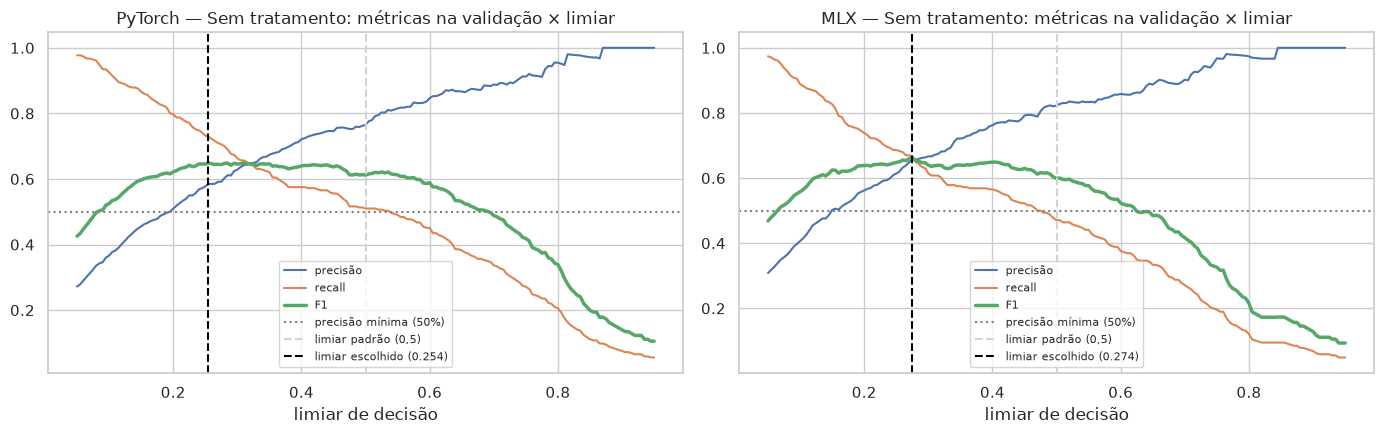

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, fw in zip(axes, FRAMEWORKS):
    p = prob_val_trat[(TRAT_FINAL, fw)]
    grade = np.linspace(0.05, 0.95, 181)
    ax.plot(grade, [precision_score(y_val, p >= t, zero_division=0) for t in grade], label="precisão")
    ax.plot(grade, [recall_score(y_val, p >= t) for t in grade], label="recall")
    ax.plot(grade, [f1_score(y_val, p >= t) for t in grade], label="F1", lw=2.5)
    ax.axhline(0.5, ls=":", color="gray", label="precisão mínima (50%)")
    ax.axvline(0.5, ls="--", color="lightgray", label="limiar padrão (0,5)")
    ax.axvline(LIMIARES[(TRAT_FINAL, fw)], ls="--", color="black",
               label=f"limiar escolhido ({LIMIARES[(TRAT_FINAL, fw)]:.3f})")
    ax.set_title(f"{fw} — {TRAT_FINAL}: métricas na validação × limiar")
    ax.set_xlabel("limiar de decisão")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
# Texto gerado a partir dos resultados
dif = f1_medio.max() - f1_medio.min()
melhoraram = tabela_limiar["F1"] >= tabela_trat["F1"] - 1e-12
lim_medio = tabela_limiar.groupby(level="tratamento")["limiar"].mean()

if dif < 0.015:
    t1 = (f"**O que vimos:** depois do ajuste do limiar, os três tratamentos ficam **praticamente empatados** em F1 "
          f"(diferença máxima de {br(dif, 3)})")
else:
    t1 = (f"**O que vimos:** depois do ajuste do limiar, o tratamento **{TRAT_FINAL}** fica à frente em F1 "
          f"({br(f1_medio.max(), 3)}, contra {br(f1_medio.min(), 3)} do pior)")
t1 += ", e " + ("todos melhoram" if melhoraram.all() else f"{melhoraram.sum()} dos {len(melhoraram)} modelos melhoram") + \
      " em relação ao limiar 0,5."
lim_sem, lim_trat = lim_medio["Sem tratamento"], lim_medio[["class_weight", "SMOTE"]].mean()
if lim_sem < lim_trat:
    t1 += (" Isso mostra que o \"efeito\" do `class_weight` e do SMOTE é, na prática, **parecido com mover o limiar**: o modelo "
           f"sem tratamento com limiar baixo (~{br(lim_sem, 2)}) se comporta como os modelos tratados com limiar mais alto "
           f"(~{br(lim_trat, 2)}).")

motivo = {
    "Sem tratamento": "Além disso, ele tem a vantagem de produzir probabilidades que correspondem à frequência real de churn.",
    "class_weight": ("Ele não cria exemplos artificiais (então não tem a limitação do SMOTE nas colunas categóricas), e o "
                     "deslocamento das probabilidades para cima é compensado pelo limiar."),
    "SMOTE": ("Mesmo com a limitação dos exemplos sintéticos nas colunas categóricas, ele teve o melhor F1 nesta execução, e o "
              "deslocamento das probabilidades para cima é compensado pelo limiar."),
}[TRAT_FINAL]
t2 = f"O tratamento escolhido é **{TRAT_FINAL}**, com o maior F1 médio na validação ({br(f1_medio[TRAT_FINAL])}). {motivo}"
if dif < 0.015:
    t2 += " Como a diferença entre os tratamentos é pequena, essa escolha tem pouco impacto prático."

t3 = ("O gráfico mostra a troca: **subir o limiar aumenta a precisão e reduz o recall**. O limiar escolhido fica no ponto de "
      "F1 máximo que ainda respeita a precisão mínima de 50%.")
mostrar("\n\n".join([t1, t2, t3]))

**O que vimos:** depois do ajuste do limiar, os três tratamentos ficam **praticamente empatados** em F1 (diferença máxima de 0,008), e todos melhoram em relação ao limiar 0,5. Isso mostra que o "efeito" do `class_weight` e do SMOTE é, na prática, **parecido com mover o limiar**: o modelo sem tratamento com limiar baixo (~0,26) se comporta como os modelos tratados com limiar mais alto (~0,63).

O tratamento escolhido é **Sem tratamento**, com o maior F1 médio na validação (0,6573). Além disso, ele tem a vantagem de produzir probabilidades que correspondem à frequência real de churn. Como a diferença entre os tratamentos é pequena, essa escolha tem pouco impacto prático.

O gráfico mostra a troca: **subir o limiar aumenta a precisão e reduz o recall**. O limiar escolhido fica no ponto de F1 máximo que ainda respeita a precisão mínima de 50%.

Os modelos finais (um por framework) são a melhor configuração da Parte 4, treinada com o tratamento escolhido, usando o limiar ajustado na validação.

Para a Regressão Logística, também ajustamos o limiar na validação com o mesmo critério, para que a comparação no teste seja justa.

In [26]:
MODELOS_FINAIS = {fw: modelos_trat[(TRAT_FINAL, fw)] for fw in FRAMEWORKS}
LIMIARES_FINAIS = {f"MLP {fw}": LIMIARES[(TRAT_FINAL, fw)] for fw in FRAMEWORKS}
LIMIARES_FINAIS["Regressão Logística"] = escolher_limiar(y_val, prob_val_rl)

print(f"Modelo final: #{ID_MELHOR} {descrever(CFG_MELHOR)} | tratamento: {TRAT_FINAL}")
for nome, lim in LIMIARES_FINAIS.items():
    print(f"  limiar de {nome:20s}: {lim:.4f}")

Modelo final: #9 3x[128-64-32] leaky_relu | lr=0.001 | dropout=0.4 | L2=0.001 | tratamento: Sem tratamento
  limiar de MLP PyTorch         : 0.2541
  limiar de MLP MLX             : 0.2744
  limiar de Regressão Logística : 0.2801


### 5.3 Avaliação final no conjunto de teste (uso único)

> 🔒 **Esta é a única vez em que o conjunto de teste é usado.** Todas as escolhas (arquitetura, tratamento do desbalanceamento, limiar) foram feitas na validação. As probabilidades de teste são calculadas **uma vez** nesta célula e reaproveitadas em todos os gráficos e tabelas abaixo.

In [27]:
PROB_TESTE = {
    "Regressão Logística": reg_log.predict_proba(X_teste)[:, 1],
    **{f"MLP {fw}": MODELOS_FINAIS[fw].prever(X_teste) for fw in FRAMEWORKS},
}

tabela_teste = pd.DataFrame({nome: metricas(y_teste, p, LIMIARES_FINAIS[nome]) for nome, p in PROB_TESTE.items()}).T
tabela_teste.insert(0, "limiar", pd.Series(LIMIARES_FINAIS))
print("Métricas no TESTE (limiares escolhidos na validação):")
tabela_teste

Métricas no TESTE (limiares escolhidos na validação):


,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC
Regressão Logística,0.2801,0.7860,0.4769,0.5410,0.5069,0.7913,0.5129
MLP PyTorch,0.2541,0.8287,0.5632,0.7016,0.6248,0.8732,0.7300
MLP MLX,0.2744,0.8553,0.6447,0.6426,0.6437,0.8704,0.7230


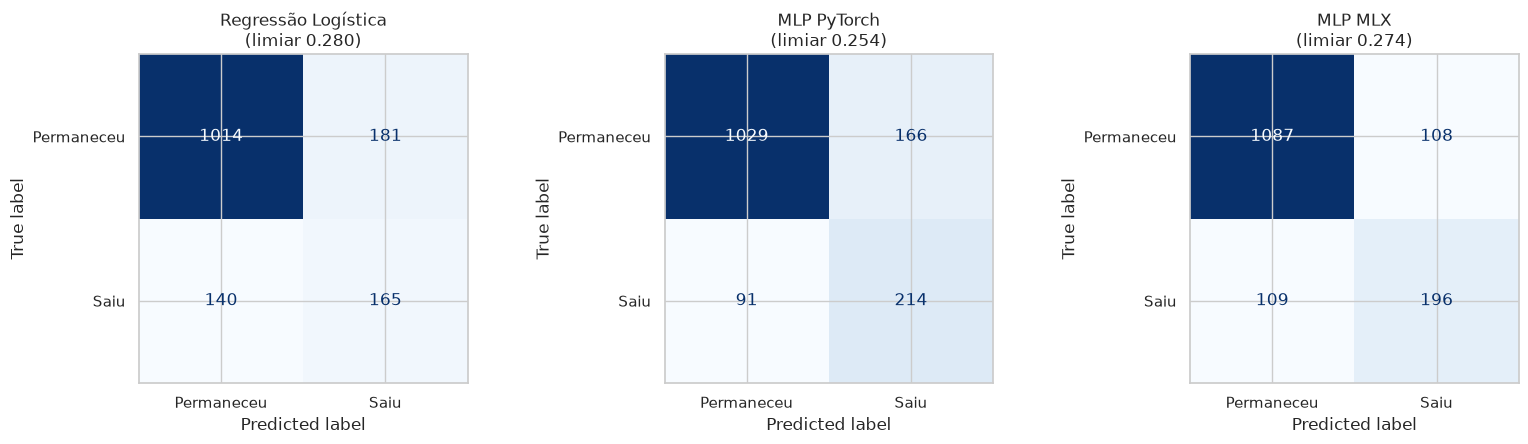

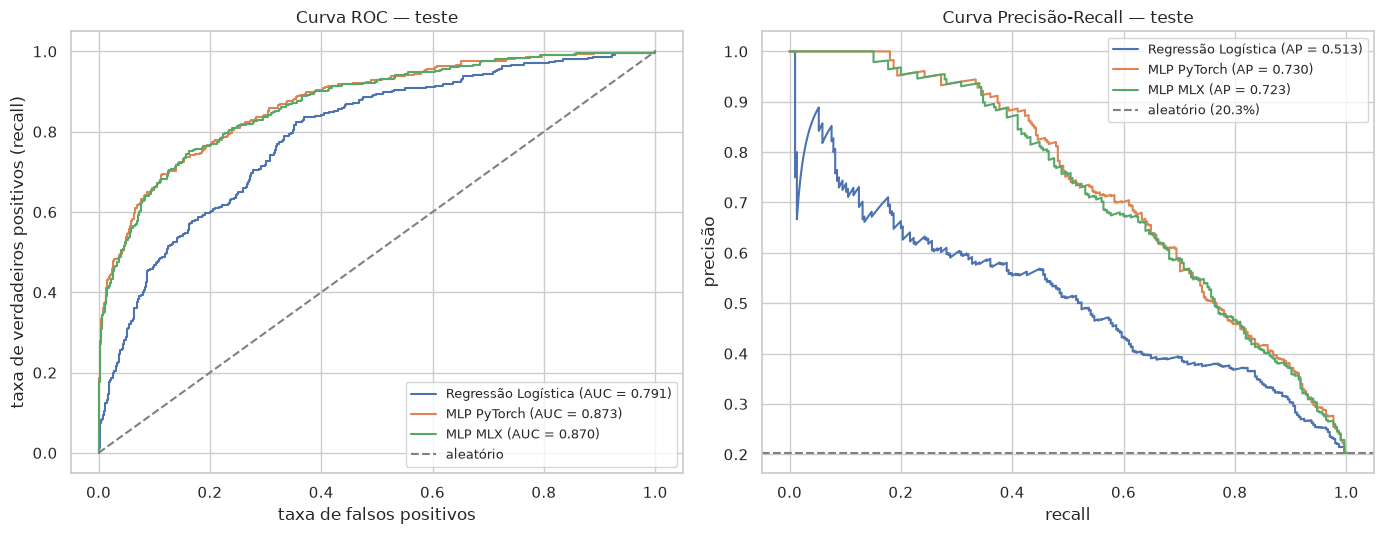

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (nome, p) in zip(axes, PROB_TESTE.items()):
    cm = confusion_matrix(y_teste, p >= LIMIARES_FINAIS[nome])
    ConfusionMatrixDisplay(cm, display_labels=["Permaneceu", "Saiu"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nome}\n(limiar {LIMIARES_FINAIS[nome]:.3f})")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nome, p in PROB_TESTE.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_teste, p)
    axes[1].plot(rec, prec, label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray", label="aleatório")
axes[0].set(title="Curva ROC — teste", xlabel="taxa de falsos positivos", ylabel="taxa de verdadeiros positivos (recall)")
axes[1].axhline(y_teste.mean(), ls="--", color="gray", label=f"aleatório ({y_teste.mean():.1%})")
axes[1].set(title="Curva Precisão-Recall — teste", xlabel="recall", ylabel="precisão")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 5.4 Rede neural × Regressão Logística no teste

In [29]:
# Texto gerado a partir dos resultados
t_rl = tabela_teste.loc["Regressão Logística"]
mlps = [f"MLP {fw}" for fw in FRAMEWORKS]
col = lambda c: tabela_teste.loc[mlps, c]
cols = ["precisão", "recall", "F1", "ROC-AUC", "PR-AUC"]
perde = [c for c in cols if (col(c) <= t_rl[c]).any()]
faixa = lambda c: f"{br(col(c).min(), 3)}–{br(col(c).max(), 3)}"

textos = ["As MLPs superam a Regressão Logística **em todas as métricas que importam** para o problema:" if not perde else
          f"As MLPs superam a Regressão Logística na maior parte das métricas (exceção: {', '.join(perde)}):"]
folga = "bem maiores" if (col("ROC-AUC") - t_rl["ROC-AUC"]).min() > 0.03 else "maiores"
textos.append(f"- **ROC-AUC e PR-AUC** {folga} (ROC-AUC de {faixa('ROC-AUC')} nas MLPs, contra {br(t_rl['ROC-AUC'], 3)}; PR-AUC "
              f"de {faixa('PR-AUC')}, contra {br(t_rl['PR-AUC'], 3)}): a rede ordena os clientes por risco melhor, como mostram "
              "as curvas ROC e Precisão-Recall acima.")
rec_ok, prec_ok = (col("recall") > t_rl["recall"]).all(), (col("precisão") > t_rl["precisão"]).all()
if rec_ok and prec_ok:
    acao = "encontra uma **parte maior dos clientes que realmente saem** (recall) **com menos alarmes falsos** (precisão)"
elif rec_ok:
    acao = "encontra uma **parte maior dos clientes que realmente saem** (recall), embora com precisão parecida ou menor"
elif prec_ok:
    acao = "sinaliza clientes com **mais acerto** (precisão maior), embora com recall parecido ou menor"
else:
    acao = None
if acao:
    textos.append(f"- Com os limiares ajustados, a rede {acao}, e tem F1 de {faixa('F1')}, contra {br(t_rl['F1'], 3)} da "
                  "Regressão Logística.")
textos.append("- A Regressão Logística, mesmo com limiar ajustado, não consegue capturar efeitos não lineares como o de "
              "`NumOfProducts` (o risco cai de 1 para 2 produtos e explode com 3–4) ou a faixa de idade de maior risco.")

auc_t, ap_t = tabela_teste["ROC-AUC"], tabela_teste["PR-AUC"]
d = max(abs(auc_t[mlps[0]] - auc_t[mlps[1]]), abs(ap_t[mlps[0]] - ap_t[mlps[1]]))
n_sinal = {m: int((PROB_TESTE[m] >= LIMIARES_FINAIS[m]).sum()) for m in mlps}
mais, menos = max(n_sinal, key=n_sinal.get), min(n_sinal, key=n_sinal.get)
fw_txt = (f"**PyTorch × MLX:** ROC-AUC de {br(auc_t['MLP PyTorch'], 3)} e {br(auc_t['MLP MLX'], 3)} e PR-AUC de "
          f"{br(ap_t['MLP PyTorch'], 3)} e {br(ap_t['MLP MLX'], 3)}, respectivamente")
if d < 0.015:
    fw_txt += (": **praticamente iguais** (as diferenças vêm só da inicialização aleatória de cada framework). Ou seja, os dois "
               "modelos **ordenam os clientes por risco igualmente bem**.")
else:
    fw_txt += ". A diferença é pequena e vem da inicialização aleatória de cada framework."
if mais != menos:
    fw_txt += (f" As diferenças em precisão e recall vêm principalmente dos **limiares**, escolhidos na validação: o {mais} "
               f"sinaliza mais clientes no teste ({n_sinal[mais]}) e o {menos}, menos ({n_sinal[menos]}).")
fw_txt += (" Isso confirma que a implementação está correta nos dois frameworks e que a escolha entre eles é uma questão de "
           "desempenho e de plataforma, não de qualidade do modelo.")
textos.append("\n" + fw_txt)

auc_val = np.mean([tabela_limiar.loc[(TRAT_FINAL, fw), "ROC-AUC"] for fw in FRAMEWORKS])
auc_tst = np.mean([auc_t[f"MLP {fw}"] for fw in FRAMEWORKS])
if auc_tst < auc_val:
    gen = (f"\nO resultado no teste fica um pouco abaixo da validação (ROC-AUC média de {br(auc_tst, 3)} contra "
           f"{br(auc_val, 3)}), o que é normal: a arquitetura e o limiar foram escolhidos na validação, então ela é levemente "
           "otimista.")
    gen += (" A diferença é pequena: o modelo **generaliza** para clientes novos." if auc_val - auc_tst < 0.03 else
            " A queda é perceptível, então os números do teste são a melhor estimativa do desempenho real.")
else:
    gen = (f"\nO resultado no teste fica no mesmo nível da validação (ROC-AUC média de {br(auc_tst, 3)} contra {br(auc_val, 3)}): "
           "o modelo **generaliza** para clientes novos.")
textos.append(gen)
mostrar("\n".join(textos))

As MLPs superam a Regressão Logística **em todas as métricas que importam** para o problema:
- **ROC-AUC e PR-AUC** bem maiores (ROC-AUC de 0,870–0,873 nas MLPs, contra 0,791; PR-AUC de 0,723–0,730, contra 0,513): a rede ordena os clientes por risco melhor, como mostram as curvas ROC e Precisão-Recall acima.
- Com os limiares ajustados, a rede encontra uma **parte maior dos clientes que realmente saem** (recall) **com menos alarmes falsos** (precisão), e tem F1 de 0,625–0,644, contra 0,507 da Regressão Logística.
- A Regressão Logística, mesmo com limiar ajustado, não consegue capturar efeitos não lineares como o de `NumOfProducts` (o risco cai de 1 para 2 produtos e explode com 3–4) ou a faixa de idade de maior risco.

**PyTorch × MLX:** ROC-AUC de 0,873 e 0,870 e PR-AUC de 0,730 e 0,723, respectivamente: **praticamente iguais** (as diferenças vêm só da inicialização aleatória de cada framework). Ou seja, os dois modelos **ordenam os clientes por risco igualmente bem**. As diferenças em precisão e recall vêm principalmente dos **limiares**, escolhidos na validação: o MLP PyTorch sinaliza mais clientes no teste (380) e o MLP MLX, menos (304). Isso confirma que a implementação está correta nos dois frameworks e que a escolha entre eles é uma questão de desempenho e de plataforma, não de qualidade do modelo.

O resultado no teste fica um pouco abaixo da validação (ROC-AUC média de 0,872 contra 0,889), o que é normal: a arquitetura e o limiar foram escolhidos na validação, então ela é levemente otimista. A diferença é pequena: o modelo **generaliza** para clientes novos.

In [30]:
# Salvando os modelos finais, o pré-processador e as configurações
caminho_pt = os.path.join(PASTA_MODELOS, "mlp_final_pytorch.pt")
caminho_mlx = os.path.join(PASTA_MODELOS, "mlp_final_mlx.safetensors")
MODELOS_FINAIS["PyTorch"].salvar(caminho_pt)
MODELOS_FINAIS["MLX"].salvar(caminho_mlx)
joblib.dump(preprocessador, os.path.join(PASTA_MODELOS, "preprocessador.joblib"))
with open(os.path.join(PASTA_MODELOS, "config_final.json"), "w", encoding="utf-8") as f:
    json.dump({"configuracao": {**CFG_MELHOR, "ocultas": list(CFG_MELHOR["ocultas"])},
               "tratamento_desbalanceamento": TRAT_FINAL, "limiares": LIMIARES_FINAIS,
               "atributos": nomes_atributos, "treinado_em": f"{platform.system()} {platform.machine()}",
               "dispositivo_mlx": str(mx.default_device())}, f, ensure_ascii=False, indent=2)

# Conferência: recarrega os dois modelos e verifica que as previsões são idênticas
args_modelo = (N_ENTRADAS, CFG_MELHOR["ocultas"], CFG_MELHOR["ativacao"], CFG_MELHOR["dropout"], CFG_MELHOR.get("norm"))
recarregado_pt = MLPTorch(*args_modelo)
recarregado_pt.load_state_dict(torch.load(caminho_pt)); recarregado_pt.eval()
recarregado_mlx = MLPMLX(*args_modelo)
recarregado_mlx.load_weights(caminho_mlx); recarregado_mlx.eval()
with torch.no_grad():
    assert np.allclose(recarregado_pt(torch.from_numpy(X_val)).numpy(), MODELOS_FINAIS["PyTorch"].prever(X_val), atol=1e-6)
assert np.allclose(np.array(recarregado_mlx(mx.array(X_val))), MODELOS_FINAIS["MLX"].prever(X_val), atol=1e-6)

for arq in sorted(os.listdir(PASTA_MODELOS)):
    print(f"  {arq:30s} {os.path.getsize(os.path.join(PASTA_MODELOS, arq)):>8,d} bytes")
print("✅ Modelos salvos e recarregados com sucesso.")
if not NO_MAC_APPLE_SILICON:
    print("MAC: rode o notebook no Mac para gerar o mlp_final_mlx.safetensors definitivo (treinado com a GPU).")

  config_final.json                   684 bytes
  mlp_final_mlx.safetensors        48,796 bytes
  mlp_final_pytorch.pt             51,993 bytes
  preprocessador.joblib             4,291 bytes
✅ Modelos salvos e recarregados com sucesso.
MAC: rode o notebook no Mac para gerar o mlp_final_mlx.safetensors definitivo (treinado com a GPU).


---
## 6. Interpretação e recomendações

### 6.1 Importância dos atributos (*Permutation Importance*)

Para cada atributo **original** (antes da codificação), embaralhamos seus valores e medimos **quanto o ROC-AUC cai**. Se o modelo depende muito de um atributo, embaralhá-lo destrói informação e a AUC cai bastante. As três colunas de `Geography` são embaralhadas juntas, como uma única variável. Repetimos 10 vezes por atributo e mostramos a média e o desvio padrão.

Usamos o **conjunto de validação**, e não o de teste, para respeitar a regra de que o teste só é usado uma vez.

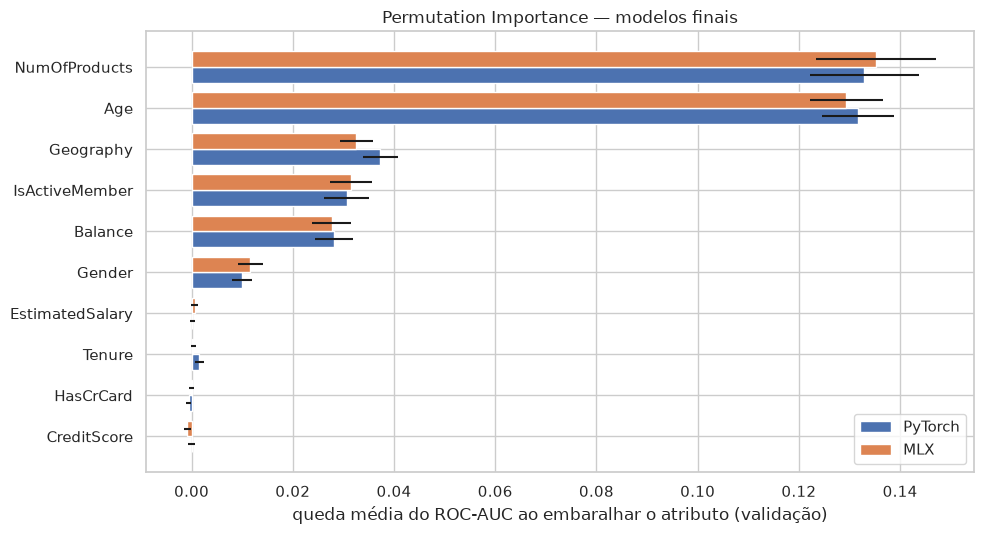

,PyTorch,MLX
NumOfProducts,0.1329,0.1353
Age,0.1317,0.1293
Geography,0.0373,0.0326
IsActiveMember,0.0307,0.0315
Balance,0.0282,0.0277
Gender,0.0099,0.0116
EstimatedSalary,0.0001,0.0006
Tenure,0.0015,0.0004
HasCrCard,-0.0006,-0.0001
CreditScore,-0.0000,-0.0008


In [31]:
def importancia_permutacao(prever, X_raw, y_true, n_repeticoes=10, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_true, prever(X_raw))
    res = {}
    for col in X_raw.columns:
        quedas = []
        for _ in range(n_repeticoes):
            Xp = X_raw.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            quedas.append(base - roc_auc_score(y_true, prever(Xp)))
        res[col] = (np.mean(quedas), np.std(quedas))
    return pd.DataFrame(res, index=["queda média de AUC", "desvio"]).T

importancias = {}
for fw in FRAMEWORKS:
    prever_fw = lambda Xr, fw=fw: MODELOS_FINAIS[fw].prever(preprocessador.transform(Xr).astype(np.float32))
    importancias[fw] = importancia_permutacao(prever_fw, X_val_raw, y_val)

ordem = importancias["MLX"]["queda média de AUC"].sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
posicoes = np.arange(len(ordem))
for k, (fw, cor) in enumerate(zip(FRAMEWORKS, ["#4C72B0", "#DD8452"])):
    imp = importancias[fw].loc[ordem]
    ax.barh(posicoes + (k - 0.5) * 0.38, imp["queda média de AUC"], xerr=imp["desvio"], height=0.38, label=fw, color=cor)
ax.set_yticks(posicoes, ordem)
ax.set_xlabel("queda média do ROC-AUC ao embaralhar o atributo (validação)")
ax.set_title("Permutation Importance — modelos finais")
ax.legend()
plt.tight_layout()
plt.show()

tabela_imp = pd.concat({fw: imp["queda média de AUC"] for fw, imp in importancias.items()}, axis=1)
tabela_imp.sort_values("MLX", ascending=False)

In [32]:
# Texto gerado a partir dos resultados (importância média nos dois frameworks)
imp = tabela_imp.mean(axis=1).sort_values(ascending=False)
pos = {c: k for k, c in enumerate(imp.index, start=1)}
ordinal = {1: "primeiro", 2: "segundo", 3: "terceiro", 4: "quarto", 5: "quinto",
           6: "sexto", 7: "sétimo", 8: "oitavo", 9: "nono", 10: "décimo"}
topo = imp.index[0]
posicao = lambda c: "o atributo mais importante" if pos[c] == 1 else f"o {ordinal[pos[c]]} atributo mais importante"
textos = ["**As hipóteses da Parte 1 se confirmam?** (posições pela importância média nos dois frameworks)"]

# H1 – idade
p_age = pos["Age"]
if p_age == 1:
    h1 = "**H1 (idade): confirmada.** `Age` é o **atributo mais importante**"
elif p_age == 2 and imp["Age"] >= 0.85 * imp.iloc[0]:
    h1 = f"**H1 (idade): confirmada.** `Age` está **praticamente empatada com `{topo}` no topo**"
elif p_age <= 3:
    h1 = f"**H1 (idade): confirmada em parte.** `Age` é o {ordinal[p_age]} atributo mais importante, atrás de `{topo}`"
else:
    h1 = f"**H1 (idade): não confirmada.** `Age` é só o {ordinal[p_age]} atributo mais importante"
textos.append(f"- {h1} (queda média de AUC de {br(imp['Age'])}).")

# H2 – engajamento e produtos
p_np, p_ia = pos["NumOfProducts"], pos["IsActiveMember"]
veredito = "confirmada" if p_np <= 3 and p_ia <= 5 else "confirmada em parte" if min(p_np, p_ia) <= 3 else "não confirmada"
h2 = f"**H2 (engajamento e produtos): {veredito}.** `NumOfProducts` é {posicao('NumOfProducts')}"
if p_np <= 2:
    h2 += (", com importância muito maior do que a análise exploratória sugeria. A rede capturou o efeito não linear do número "
           "de produtos (risco baixo com 2, altíssimo com 3–4), que a Regressão Logística não consegue representar, o que ajuda "
           "a explicar a diferença de desempenho entre os dois modelos")
h2 += (f". `IsActiveMember` é o {ordinal[p_ia]}, com importância de cerca de {pct(imp['IsActiveMember'] / imp['Age'])} "
       "da importância da idade.")
textos.append(f"- {h2}")

# H3 – Alemanha
p_geo = pos["Geography"]
saldo_zero = df.groupby("Geography")["Balance"].apply(lambda s: (s == 0).mean())
alemanha = "**nenhum** cliente tem" if saldo_zero["Germany"] == 0 else f"{pct(saldo_zero['Germany'])} dos clientes têm"
veredito = "confirmada" if p_geo <= 3 else "confirmada em parte" if p_geo <= 5 else "não confirmada"
textos.append(f"- **H3 (Alemanha): {veredito}.** `Geography` é {posicao('Geography')}. Parte desse efeito "
              f"pode estar ligada a `Balance` ({ordinal[pos['Balance']]} lugar): na Alemanha, {alemanha} saldo zero, contra "
              f"{pct(saldo_zero['France'])} na França e {pct(saldo_zero['Spain'])} na Espanha.")

# Demais atributos
citados = {"Age", "NumOfProducts", "IsActiveMember", "Geography", "Balance"}
nulos = [c for c in imp.index if imp[c] < 0.005 and c not in citados]
pequenos = [c for c in imp.index if c not in citados and c not in nulos]
codigo = lambda cs: ", ".join(f"`{c}`" for c in cs)
resto = []
if nulos:
    frase = f"{codigo(nulos)} {'tem' if len(nulos) == 1 else 'têm'} importância praticamente nula (queda de AUC abaixo de 0,005)"
    if "CreditScore" in nulos:
        frase += ", o que combina com a Parte 1, em que `CreditScore` tinha distribuições quase iguais nas duas classes"
    resto.append(frase + ".")
if pequenos:
    resto.append(f"{codigo(pequenos)} {'tem' if len(pequenos) == 1 else 'têm'} um efeito pequeno.")
if resto:
    textos.append("- " + " ".join(resto))
mostrar("\n".join(textos))

**As hipóteses da Parte 1 se confirmam?** (posições pela importância média nos dois frameworks)
- **H1 (idade): confirmada.** `Age` está **praticamente empatada com `NumOfProducts` no topo** (queda média de AUC de 0,1305).
- **H2 (engajamento e produtos): confirmada.** `NumOfProducts` é o atributo mais importante, com importância muito maior do que a análise exploratória sugeria. A rede capturou o efeito não linear do número de produtos (risco baixo com 2, altíssimo com 3–4), que a Regressão Logística não consegue representar, o que ajuda a explicar a diferença de desempenho entre os dois modelos. `IsActiveMember` é o quarto, com importância de cerca de 24% da importância da idade.
- **H3 (Alemanha): confirmada.** `Geography` é o terceiro atributo mais importante. Parte desse efeito pode estar ligada a `Balance` (quinto lugar): na Alemanha, **nenhum** cliente tem saldo zero, contra 48% na França e 48% na Espanha.
- `Tenure`, `EstimatedSalary`, `HasCrCard`, `CreditScore` têm importância praticamente nula (queda de AUC abaixo de 0,005), o que combina com a Parte 1, em que `CreditScore` tinha distribuições quase iguais nas duas classes. `Gender` tem um efeito pequeno.

### 6.2 Previsão para um cliente novo

Cliente: **França, masculino, 40 anos, CreditScore 600, Tenure 3, Balance 60.000, 2 produtos, possui cartão, cliente ativo, salário estimado de 50.000.**

O cliente passa pelo **mesmo pré-processador** (ajustado no treino) antes de entrar nos modelos.

In [33]:
cliente = pd.DataFrame([{
    "CreditScore": 600, "Geography": "France", "Gender": "Male", "Age": 40, "Tenure": 3,
    "Balance": 60000.0, "NumOfProducts": 2, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 50000.0,
}])[X.columns]
x_cliente = preprocessador.transform(cliente).astype(np.float32)

previsoes = {
    "Regressão Logística": float(reg_log.predict_proba(x_cliente)[0, 1]),
    **{f"MLP {fw}": float(MODELOS_FINAIS[fw].prever(x_cliente)[0]) for fw in FRAMEWORKS},
}
for nome, p in previsoes.items():
    decisao = "VAI SAIR (acionar retenção)" if p >= LIMIARES_FINAIS[nome] else "deve permanecer"
    print(f"{nome:20s}: probabilidade de churn = {p:6.2%} | limiar {LIMIARES_FINAIS[nome]:.3f} → {decisao}")

Regressão Logística : probabilidade de churn =  7.29% | limiar 0.280 → deve permanecer
MLP PyTorch         : probabilidade de churn =  4.92% | limiar 0.254 → deve permanecer
MLP MLX             : probabilidade de churn =  3.13% | limiar 0.274 → deve permanecer


In [34]:
# Texto gerado a partir dos resultados
sinalizado = {nome: p >= LIMIARES_FINAIS[nome] for nome, p in previsoes.items()}
probs = f"{pct(previsoes['MLP PyTorch'], 1)} no PyTorch e {pct(previsoes['MLP MLX'], 1)} no MLX"
perfil = ("ele tem **2 produtos** (o grupo com menor churn, ~8%), é **cliente ativo**, mora na **França** (taxa abaixo da média) "
          "e é homem. A idade de 40 anos é o único fator de alerta, pois está no início da faixa de maior risco.")
if not any(sinalizado.values()):
    texto = (f"**Interpretação:** o cliente tem **baixa probabilidade de churn** segundo a rede neural ({probs}), abaixo do limiar "
             f"de decisão, então ele **não** seria sinalizado para ações de retenção. Isso faz sentido com a análise exploratória: "
             f"{perfil} Os três modelos concordam com a decisão.")
elif all(sinalizado.values()):
    texto = (f"**Interpretação:** os três modelos sinalizam o cliente para ações de retenção ({probs} na rede neural), mesmo com "
             f"um perfil de risco aparentemente baixo: {perfil} Para os modelos, esse fator pesou mais que os de proteção.")
else:
    quem = ", ".join(n for n, s in sinalizado.items() if s)
    texto = (f"**Interpretação:** os modelos discordam: só {quem} sinaliza o cliente ({probs} na rede neural). Ele é um caso "
             f"de fronteira, com probabilidade perto do limiar. Pela análise exploratória, {perfil}")
mostrar(texto)

**Interpretação:** o cliente tem **baixa probabilidade de churn** segundo a rede neural (4,9% no PyTorch e 3,1% no MLX), abaixo do limiar de decisão, então ele **não** seria sinalizado para ações de retenção. Isso faz sentido com a análise exploratória: ele tem **2 produtos** (o grupo com menor churn, ~8%), é **cliente ativo**, mora na **França** (taxa abaixo da média) e é homem. A idade de 40 anos é o único fator de alerta, pois está no início da faixa de maior risco. Os três modelos concordam com a decisão.

### 6.3 Resumo executivo para a diretoria

O resumo abaixo é gerado a partir dos resultados do notebook, para que os números fiquem sempre corretos (inclusive quando o notebook é executado de novo no Mac). Ele tem no máximo 200 palavras.

In [35]:
r = tabela_teste.loc["MLP MLX"]
rl = tabela_teste.loc["Regressão Logística"]
n_saidas = int(y_teste.sum())
encontrados = int(((PROB_TESTE["MLP MLX"] >= LIMIARES_FINAIS["MLP MLX"]) & (y_teste == 1)).sum())
top3 = list(tabela_imp.sort_values("MLX", ascending=False).index[:3])
nomes_pt = {"Age": "idade", "NumOfProducts": "número de produtos", "IsActiveMember": "atividade do cliente",
            "Geography": "país", "Balance": "saldo", "Gender": "gênero", "CreditScore": "score de crédito",
            "Tenure": "tempo de casa", "EstimatedSalary": "salário", "HasCrCard": "cartão de crédito"}

resumo_executivo = f'''**Resumo executivo — Previsão de churn**

**O que o modelo faz:** uma rede neural analisa o perfil de cada cliente e estima a probabilidade de ele encerrar a conta, gerando uma lista priorizada para a equipe comercial agir antes da saída.

**Quão bem funciona:** em clientes que o modelo nunca viu, ele identificou **{r['recall']:.0%} dos clientes que realmente saíram** ({encontrados} de {n_saidas}). De cada 10 clientes sinalizados, cerca de **{r['precisão']*10:.0f} de fato saíram**. A capacidade de distinguir quem sai de quem fica (AUC de {br(r['ROC-AUC'], 2)}) é bem superior à de um modelo estatístico tradicional (AUC de {br(rl['ROC-AUC'], 2)}).

**Principais fatores de saída:** {nomes_pt[top3[0]]}, {nomes_pt[top3[1]]} e {nomes_pt[top3[2]]}.

**Recomendações:**
1. Rodar o modelo mensalmente e contatar os clientes sinalizados com ofertas personalizadas.
2. Criar um programa de relacionamento para clientes de 40 a 60 anos.
3. Reativar clientes inativos com benefícios por uso.
4. Incentivar o segundo produto, revisando a venda de 3 ou mais, que tem churn altíssimo.
5. Investigar as causas do churn elevado na Alemanha.'''

mostrar(resumo_executivo)
n_palavras = len(resumo_executivo.replace("*", "").split())
print(f"Número de palavras: {n_palavras}")
assert n_palavras <= 200, "O resumo executivo passou de 200 palavras!"

**Resumo executivo — Previsão de churn**

**O que o modelo faz:** uma rede neural analisa o perfil de cada cliente e estima a probabilidade de ele encerrar a conta, gerando uma lista priorizada para a equipe comercial agir antes da saída.

**Quão bem funciona:** em clientes que o modelo nunca viu, ele identificou **64% dos clientes que realmente saíram** (196 de 305). De cada 10 clientes sinalizados, cerca de **6 de fato saíram**. A capacidade de distinguir quem sai de quem fica (AUC de 0,87) é bem superior à de um modelo estatístico tradicional (AUC de 0,79).

**Principais fatores de saída:** número de produtos, idade e país.

**Recomendações:**
1. Rodar o modelo mensalmente e contatar os clientes sinalizados com ofertas personalizadas.
2. Criar um programa de relacionamento para clientes de 40 a 60 anos.
3. Reativar clientes inativos com benefícios por uso.
4. Incentivar o segundo produto, revisando a venda de 3 ou mais, que tem churn altíssimo.
5. Investigar as causas do churn elevado na Alemanha.

Número de palavras: 167


---
## 7. Extra: otimização com MLX (*MAC*)

O MLX é o framework de *machine learning* da Apple, feito para os chips **Apple Silicon**: CPU e GPU compartilham a mesma memória (*unified memory*), então não há cópia de dados entre elas, e as operações são executadas de forma **preguiçosa** (*lazy*), só quando o resultado é necessário.

Neste notebook, usamos duas otimizações do MLX:
1. **`mx.compile`:** o passo de treino (forward, backward e atualização do Adam) é compilado num único grafo, o que funde operações e reduz o custo de cada chamada. Isso faz diferença principalmente em redes pequenas como a nossa, em que o tempo de cada lote é dominado por esse custo fixo, e não pelo cálculo em si.
2. **GPU via Metal** (só no Mac): o MLX usa a GPU automaticamente, sem mudar o código.

A célula abaixo mede o **tempo médio por época** (só o treino, sem avaliação) da melhor configuração em três variantes: PyTorch, MLX sem compilação e MLX com `mx.compile`.

> **MAC:** fora do Mac com Apple Silicon, o MLX roda em CPU e esta comparação **não representa** o desempenho real dele. Os números definitivos desta seção são os da execução no Mac.

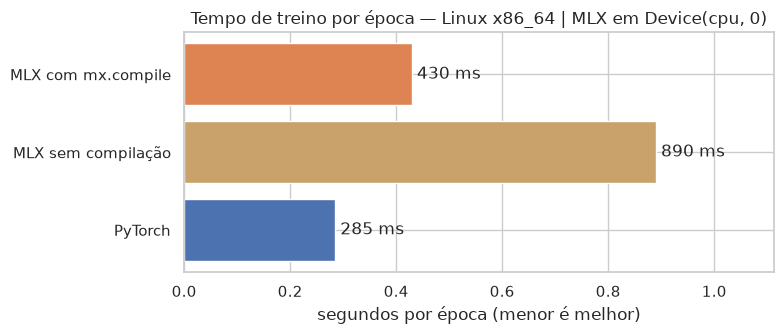

                    segundos por época
PyTorch                         0.2850
MLX sem compilação              0.8902
MLX com mx.compile              0.4296

Ganho do mx.compile sobre o MLX sem compilação: 2.07x
MAC: resultado medido em CPU (fora do Mac). Rode esta célula no Mac com Apple Silicon para o resultado real.


In [36]:
def tempo_por_epoca(criar, epocas=5, batch_size=32, seed=SEED):
    fixar_sementes(seed)
    ad = criar()
    ad.preparar(X_treino, y_treino, np.ones(len(y_treino), dtype=np.float32))
    rng = np.random.default_rng(seed)
    def uma_epoca():
        ordem = rng.permutation(len(y_treino))
        for i in range(0, len(ordem), batch_size):
            ad.treinar_lote(ordem[i:i + batch_size])
    uma_epoca()                                  # aquecimento (compilação, alocação de memória)
    inicio = time.perf_counter()
    for _ in range(epocas):
        uma_epoca()
    return (time.perf_counter() - inicio) / epocas

variantes = {
    "PyTorch": lambda: AdaptadorTorch(CFG_MELHOR, N_ENTRADAS),
    "MLX sem compilação": lambda: AdaptadorMLX(CFG_MELHOR, N_ENTRADAS, compilar=False),
    "MLX com mx.compile": lambda: AdaptadorMLX(CFG_MELHOR, N_ENTRADAS, compilar=True),
}
bench = pd.Series({nome: tempo_por_epoca(criar) for nome, criar in variantes.items()}, name="segundos por época")

ambiente = f"{platform.system()} {platform.machine()} | MLX em {mx.default_device()}"
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(bench.index, bench.values, color=["#4C72B0", "#C9A26B", "#DD8452"])
for i, v in enumerate(bench.values):
    ax.text(v, i, f" {v*1000:.0f} ms", va="center")
ax.set_xlabel("segundos por época (menor é melhor)")
ax.set_title(f"Tempo de treino por época — {ambiente}")
ax.set_xlim(0, bench.max() * 1.25)
plt.tight_layout()
plt.show()

print(bench.to_frame())
print(f"\nGanho do mx.compile sobre o MLX sem compilação: {bench['MLX sem compilação'] / bench['MLX com mx.compile']:.2f}x")
if not NO_MAC_APPLE_SILICON:
    print("MAC: resultado medido em CPU (fora do Mac). Rode esta célula no Mac com Apple Silicon para o resultado real.")

In [37]:
# Texto gerado a partir dos resultados
ms = lambda v: f"{v * 1000:.0f} ms"
mais_rapido = bench.idxmin()
ganho_compile = bench["MLX sem compilação"] / bench["MLX com mx.compile"]
razao = bench["PyTorch"] / bench["MLX com mx.compile"]

if NO_MAC_APPLE_SILICON:
    t1 = ("**Como interpretar:** nesta execução no Mac, o MLX rodou na **GPU (Metal)** e o PyTorch na **CPU** (o código do "
          f"PyTorch não usa a GPU do Mac). O mais rápido foi **{mais_rapido}** ({ms(bench.min())} por época).")
else:
    t1 = ("**Como interpretar:** nesta execução fora do Mac, o MLX e o PyTorch rodaram na **CPU**. O mais rápido foi "
          f"**{mais_rapido}** ({ms(bench.min())} por época). Em CPU, o PyTorch tende a ser mais rápido que o MLX, que não foi "
          "feito para esse cenário.")
t1 += (f" O MLX com `mx.compile` ficou {br(ganho_compile, 2)}x {'mais rápido' if ganho_compile >= 1 else 'mais lento'} que "
       "sem compilação e " + (f"{br(razao, 2)}x mais rápido" if razao >= 1 else f"{br(1 / razao, 2)}x mais lento") +
       " que o PyTorch.")

t2 = ("O `mx.compile` funde as operações de cada passo e elimina parte do seu custo fixo; o efeito tende a ser maior na GPU, "
      "onde cada operação separada também tem o custo de ser enviada para ela. Com lotes de 32 exemplos e uma rede de alguns "
      "milhares de parâmetros, cada lote é um cálculo minúsculo, e o custo fixo de cada chamada (no Python e no framework) pesa "
      "mais que o cálculo em si.")
if NO_MAC_APPLE_SILICON and razao > 1.5:
    t2 += (" Mesmo assim, a GPU já traz ganho nesta base pequena, e ele tende a crescer com **lotes maiores e redes maiores**.")
elif NO_MAC_APPLE_SILICON:
    t2 += (" Por isso, nesta base pequena, **a GPU não traz um ganho grande**: o benefício do Apple Silicon aparece mais "
           "claramente com **lotes maiores e redes maiores**.")
else:
    t2 += (" Por isso, nesta base pequena, mesmo a GPU não deve trazer um ganho grande. Na execução no Mac, o MLX roda na GPU e "
           "esta comparação mostra o desempenho real dele.")
mostrar("\n\n".join([t1, t2]))

**Como interpretar:** nesta execução fora do Mac, o MLX e o PyTorch rodaram na **CPU**. O mais rápido foi **PyTorch** (285 ms por época). Em CPU, o PyTorch tende a ser mais rápido que o MLX, que não foi feito para esse cenário. O MLX com `mx.compile` ficou 2,07x mais rápido que sem compilação e 1,51x mais lento que o PyTorch.

O `mx.compile` funde as operações de cada passo e elimina parte do seu custo fixo; o efeito tende a ser maior na GPU, onde cada operação separada também tem o custo de ser enviada para ela. Com lotes de 32 exemplos e uma rede de alguns milhares de parâmetros, cada lote é um cálculo minúsculo, e o custo fixo de cada chamada (no Python e no framework) pesa mais que o cálculo em si. Por isso, nesta base pequena, mesmo a GPU não deve trazer um ganho grande. Na execução no Mac, o MLX roda na GPU e esta comparação mostra o desempenho real dele.

---
## 8. Questões teóricas

**1. Por que a função sigmoide é usada na camada de saída e a ReLU nas camadas ocultas?**
A sigmoide transforma qualquer número real num valor entre 0 e 1, que pode ser interpretado como a **probabilidade** de o cliente sair. Junto com a *binary cross-entropy*, ela forma a combinação natural para classificação binária. Nas camadas ocultas, porém, a sigmoide tem um problema: para entradas grandes (positivas ou negativas), a curva fica "achatada" e a derivada fica próxima de zero, o que faz os gradientes **desaparecerem** ao atravessar várias camadas e a rede parar de aprender. A **ReLU** (`max(0, x)`) tem derivada 1 para entradas positivas, então não sofre desse problema; além disso, é muito barata de calcular e gera ativações esparsas (muitos zeros). Ela fornece a não linearidade de que a rede precisa sem prejudicar o fluxo do gradiente.

**2. Explique o papel do *backpropagation* e do gradiente descendente no treinamento.**
O treino busca os pesos que **minimizam a perda** (o quanto as previsões erram). O **gradiente descendente** é a estratégia de otimização: a cada passo, cada peso é ajustado um pouco na **direção oposta ao gradiente** da perda, ou seja, na direção em que o erro diminui mais rápido; o tamanho do passo é a **taxa de aprendizado**. O **backpropagation** é o algoritmo que **calcula esse gradiente** de forma eficiente: depois de calcular a saída (*forward*), ele percorre a rede de trás para frente aplicando a **regra da cadeia**, descobrindo quanto cada peso contribuiu para o erro. Em resumo, o backpropagation diz "para onde" e "quanto" cada peso deve mudar, e o gradiente descendente (aqui na versão Adam, com lotes de 32 exemplos) faz a mudança, repetindo o processo a cada lote e a cada época.

**3. Uma rede sem camadas ocultas, com saída sigmoide, equivale a qual modelo clássico? Por que isso importa para a comparação da Parte 3?**
Equivale à **Regressão Logística**: a saída é `sigmoide(w·x + b)`, exatamente a mesma fórmula, treinada com a mesma perda (*binary cross-entropy*). Isso importa porque mostra que a Regressão Logística é o **caso particular mais simples** de uma rede neural. Ao compará-las, estamos medindo diretamente **o ganho trazido pelas camadas ocultas**, ou seja, pela capacidade de modelar relações **não lineares** e interações entre atributos. Se a MLP não superasse a Regressão Logística, a complexidade extra não se justificaria. Como ela supera claramente, sabemos que existem padrões não lineares relevantes nos dados (como o efeito de `NumOfProducts` e da idade).

**4. Por que a acurácia pode ser enganosa nesta base? Qual seria a acurácia de um modelo que sempre prevê "não sai"?**
Porque as classes são desbalanceadas: só 20,37% dos clientes saem. Um modelo que **sempre prevê "não sai"** acerta todos os 7.963 clientes que ficam e erra os 2.037 que saem, ou seja, tem **acurácia de 79,63%** sem ter aprendido nada e sem identificar **nenhum** cliente em risco (recall = 0). Uma acurácia de 85%, por exemplo, parece ótima, mas é pouco melhor que esse modelo trivial. Por isso usamos métricas que olham para a classe minoritária: **recall, precisão, F1, ROC-AUC e PR-AUC**.

**5. Para o banco, o que custa mais: um falso negativo ou um falso positivo? Como isso deve influenciar a escolha do limiar?**
Em geral, o **falso negativo custa mais**: é um cliente que vai sair e que o modelo não sinalizou, então o banco perde **toda a receita futura** dele (e trazer um cliente novo costuma custar bem mais do que manter um atual). O **falso positivo** é um cliente que ficaria de qualquer jeito, mas recebeu uma ação de retenção; o custo é o da ação (uma ligação, um desconto), normalmente bem menor. Por isso, o limiar deve ficar **abaixo de 0,5**, favorecendo o **recall** (encontrar mais clientes que vão sair), aceitando mais alarmes falsos. Mas isso tem limite: se a precisão ficar muito baixa, a equipe comercial desperdiça esforço e o cliente pode ficar incomodado com contatos desnecessários. Foi por isso que escolhemos o limiar que maximiza o F1 com **precisão mínima de 50%**. Com dados reais de custo (valor médio de um cliente e custo de uma ação), o ideal seria escolher o limiar que **minimiza o custo total esperado**.

---
## 9. Entregáveis

A célula abaixo gera o `requirements.txt` com as versões **realmente usadas** nesta execução. O MLX aparece com marcadores de plataforma, para que o mesmo arquivo funcione no Mac (GPU) e no Linux (CPU).

In [38]:
from importlib.metadata import version

pacotes = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "imbalanced-learn", "torch", "joblib", "jupyter"]
linhas = [f"# Gerado pelo notebook em {platform.system()} {platform.machine()}, Python {platform.python_version()}"]
linhas += [f"{p}=={version(p).split('+')[0]}" for p in pacotes]
linhas.append(f"mlx=={mx.__version__}")
linhas.append(f'mlx-cpu=={mx.__version__}; sys_platform == "linux"   # só no Linux (no Mac o mlx já usa a GPU)')
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(linhas) + "\n")
print(open("requirements.txt", encoding="utf-8").read())

# Gerado pelo notebook em Linux x86_64, Python 3.14.4
numpy==2.5.5
pandas==3.1.1
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
imbalanced-learn==0.14.2
torch==2.15.0
joblib==1.6.0
jupyter==1.1.1
mlx==0.32.4
mlx-cpu==0.32.4; sys_platform == "linux"   # só no Linux (no Mac o mlx já usa a GPU)



**Checklist de entrega** (`churn_rna_<seu_nome>.zip`):
- ☐ `churn_rna.ipynb`, executado do início ao fim, sem erros, com todas as saídas visíveis (**MAC:** execução final no Mac);
- ☐ `requirements.txt` (gerado pela célula acima);
- ☐ modelos finais na pasta `modelos/`: `mlp_final_mlx.safetensors` (MLX) e `mlp_final_pytorch.pt` (PyTorch), mais o pré-processador e a configuração.